# GPSA Analysis - WT vs S466R

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from io import StringIO


## Delta Energy Terms

### Load data

In [5]:
def load_finalenergy (mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = (f'../../data/1bf5/{mut}/rep{rep}/analysis/006_gbsa_8A/FINAL_ENERGY.csv')
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the index of the line containing "Delta Energy Terms"
        start_idx = None
        for i, line in enumerate(lines):
            if "Delta Energy Terms" in line:
                start_idx = i + 1  # Start from the next line
                break

        if start_idx is None:
            raise ValueError("Section 'Delta Energy Terms' not found in the file")

        # Extract the lines after "Delta Energy Terms"
        data_lines = lines[start_idx:]
        data_string = ''.join(data_lines)
        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)
    return dfs


In [6]:
wt_delta_dfs = load_finalenergy('wt')
S466R_delta_dfs = load_finalenergy('S466R')

In [7]:
wt_delta_dfs[0].head()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
0,1000,0.0,0.0,0.0,-133.98,-277.39,0.0,0.0,260.99,-18.82,-411.37,242.17,-169.21
1,1001,0.0,0.0,0.0,-137.18,-297.28,-0.0,-0.0,281.92,-18.93,-434.46,262.98,-171.48
2,1002,-0.0,-0.0,-0.0,-135.61,-299.07,-0.0,0.0,282.32,-20.45,-434.68,261.87,-172.81
3,1003,0.0,0.0,0.0,-134.28,-298.42,0.0,0.0,283.22,-19.71,-432.69,263.52,-169.18
4,1004,-0.0,-0.0,0.0,-131.69,-282.88,-0.0,0.0,266.81,-19.98,-414.57,246.83,-167.74


Columns: 
- BOND: Bond stretching energy
- ANGLE: Angle bending energy
- DIHED: Dihedral (torsional) energy
- VDWAALS: van der Waals energy
- EEL: Electrostatic energy
- 1-4 VDW: 1-4 van der Waals energy
- 1-4 EEL: 1-4 Electrostatic energy
- EGB: Generalized Born energy
- ESURF: Surface (non-polar solvation) energy
- GGAS: Gas-phase energy. (BOND + ANGLE + DIHED + VDWAALS + EEL + 1-4 VDW + 1-4 EEL)
- GSOLV: Solvation energy. (EGB + ESURF)
- TOTAL: Total energy. (GGAS + GSOLV)

### By replicate

Plot delta energy terms by replicate.

In [8]:
wt_delta_dfs[0].describe()

,Frame #,BOND,ANGLE,DIHED,VDWAALS,EEL,1-4 VDW,1-4 EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
count,1002.000000,1002.0,1002.0,1002.0,1002.000000,1002.000000,1002.0,1002.0,1002.000000,1002.000000,1002.000000,1002.000000,1002.000000
mean,1500.500000,0.0,0.0,0.0,-147.208054,-321.256806,0.0,0.0,304.558393,-19.942605,-468.464551,284.615729,-183.848743
std,289.396786,0.0,0.0,0.0,9.438355,25.177154,0.0,0.0,23.818368,0.911887,27.355557,23.564614,9.822645
min,1000.000000,-0.0,0.0,0.0,-176.550000,-398.030000,0.0,-0.0,242.260000,-22.610000,-551.770000,222.510000,-217.090000
25%,1250.250000,0.0,0.0,0.0,-154.020000,-337.855000,0.0,0.0,288.500000,-20.540000,-486.032500,268.350000,-190.877500
50%,1500.500000,0.0,0.0,0.0,-147.720000,-318.480000,0.0,0.0,302.130000,-19.970000,-466.715000,282.260000,-184.310000
75%,1750.750000,0.0,-0.0,0.0,-140.545000,-304.205000,0.0,0.0,320.137500,-19.330000,-450.807500,299.782500,-176.625000
max,2001.000000,-0.0,0.0,0.0,-120.250000,-253.990000,0.0,-0.0,378.590000,-17.110000,-391.460000,358.500000,-156.460000


In [9]:
wt_delta_summary = []

for df in wt_delta_dfs:
    desc = df.describe()
    desc = desc.filter(items = ['mean', 'std'], axis=0)
    desc.loc['sem'] = df.sem()
    desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
    wt_delta_summary.append(desc)

S466R_delta_summary = []

for df in S466R_delta_dfs:
    desc = df.describe()
    desc = desc.filter(items = ['mean', 'std'], axis=0)
    desc.loc['sem'] = df.sem()
    desc = desc.drop(['Frame #', 'BOND', 'ANGLE', 'DIHED', '1-4 VDW', '1-4 EEL'], axis=1)
    S466R_delta_summary.append(desc)

In [10]:
wt_delta_summary[0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-147.208054,-321.256806,304.558393,-19.942605,-468.464551,284.615729,-183.848743
std,9.438355,25.177154,23.818368,0.911887,27.355557,23.564614,9.822645
sem,0.298169,0.795377,0.752451,0.028808,0.864195,0.744434,0.310309


In [11]:
S466R_delta_summary[0]

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-108.446008,-458.894092,435.424202,-15.979142,-567.339900,419.445010,-147.894950
std,8.386016,21.134896,19.891451,1.124474,22.952805,19.668129,8.966867
sem,0.264924,0.667677,0.628395,0.035523,0.725107,0.621340,0.283274


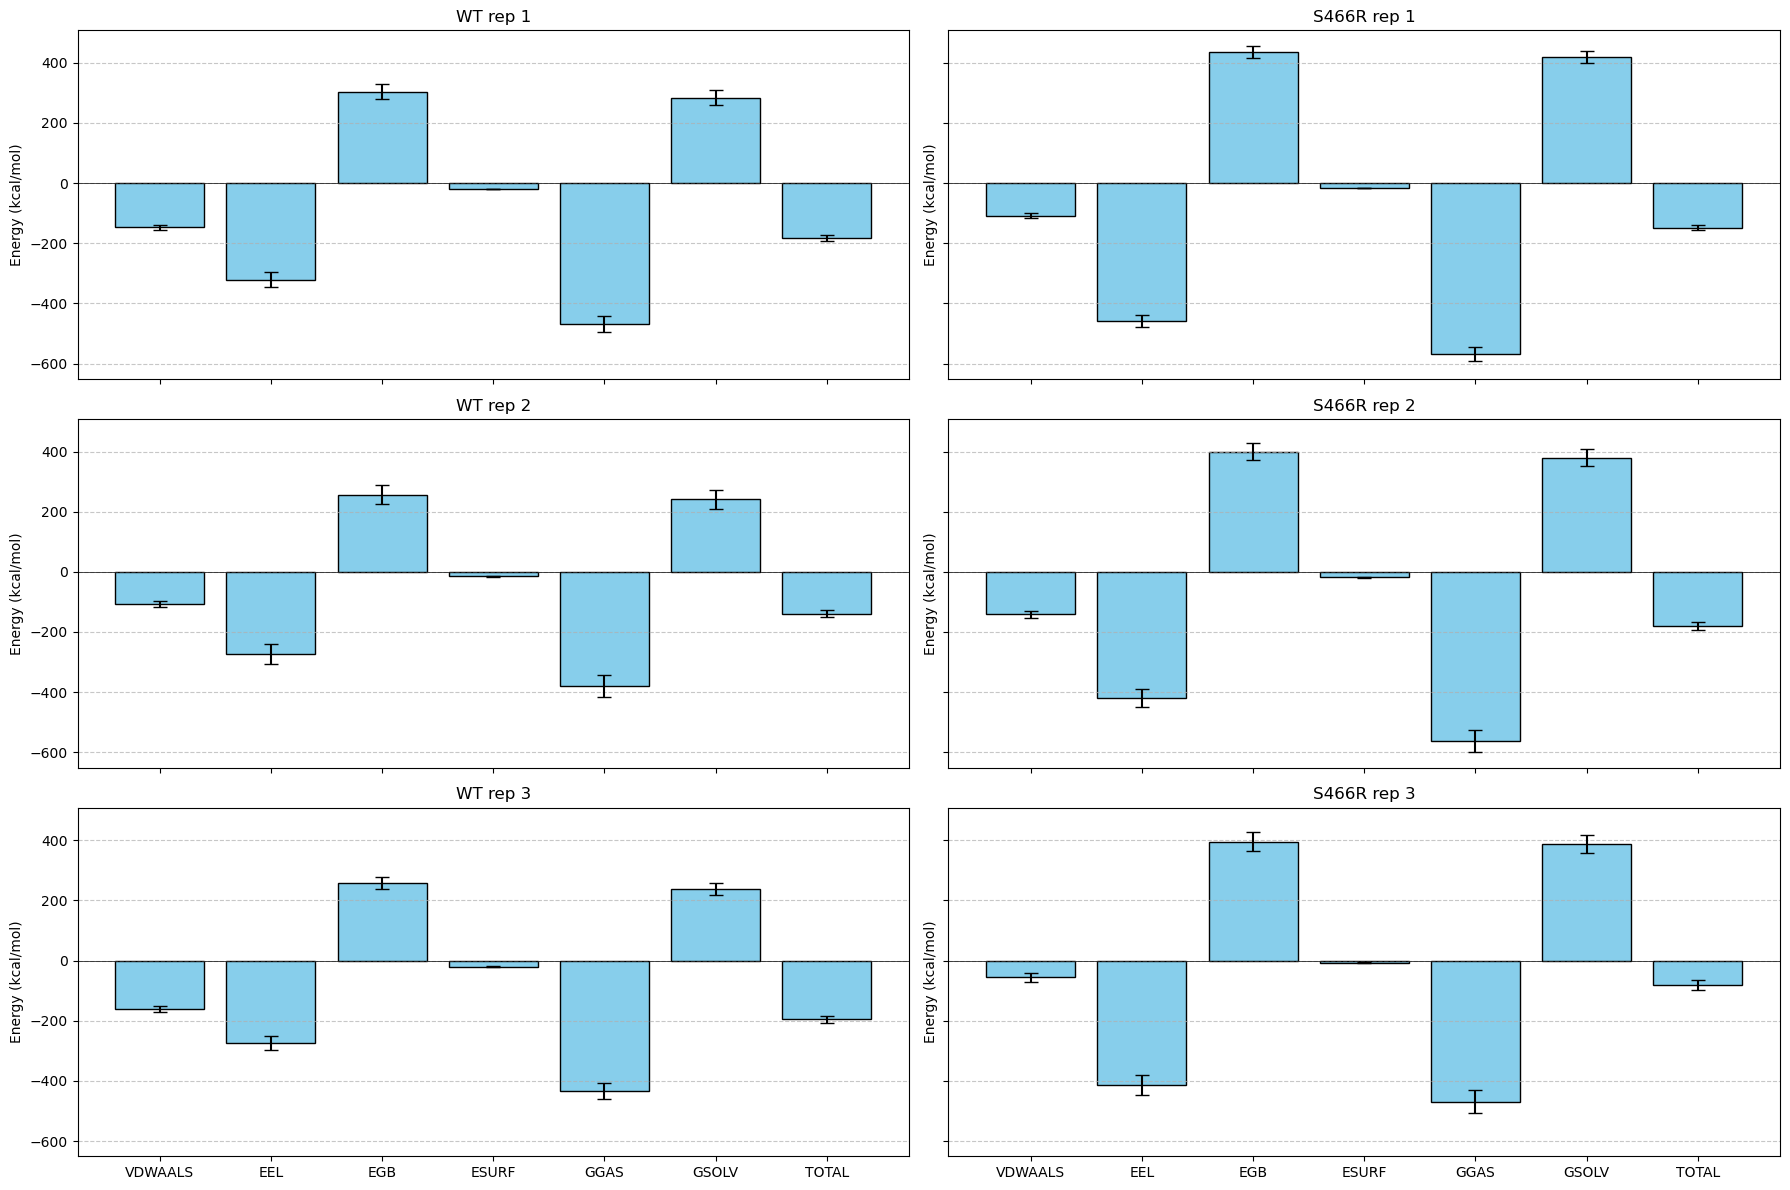

In [12]:

# Find global min and max
all_data = [
    wt_delta_summary[0].transpose().values,
    wt_delta_summary[1].transpose().values,
    wt_delta_summary[2].transpose().values,
    S466R_delta_summary[0].transpose().values,
    S466R_delta_summary[1].transpose().values,
    S466R_delta_summary[2].transpose().values
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(3, 2, figsize=(18, 12), sharey=True, sharex=True)
ax1, ax2, ax3, ax4, ax5, ax6 = axes.flatten()

plots = [
    (wt_delta_summary[0].transpose(), ax1, 'WT rep 1'),
    (S466R_delta_summary[0].transpose(), ax2, 'S466R rep 1'),
    (wt_delta_summary[1].transpose(), ax3, 'WT rep 2'),
    (S466R_delta_summary[1].transpose(), ax4, 'S466R rep 2'),
    (wt_delta_summary[2].transpose(), ax5, 'WT rep 3'),
    (S466R_delta_summary[2].transpose(), ax6, 'S466R rep 3'),
]

for df, ax, title in plots:
    ax.bar(df.index, df['mean'], yerr=df['std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)


plt.tight_layout()
plt.show()

#### Interpretation


### By mutation (combining replicates)

In [13]:
def combine_delta(dfs):
    combined_means = []
    combined_stds = []

    # Combine for each energy term
    for col in dfs[0].columns:
        means = [df.loc['mean', col] for df in dfs]
        stds = [df.loc['std', col] for df in dfs]
        
        # Simple mean 
        combined_mean = np.mean(means)
        
        # Pooled variance and combined std
        variances = [s**2 for s in stds]
        pooled_variance = np.mean(variances)  # Since n_frames is the same, (n-1) terms cancel out
        combined_std = np.sqrt(pooled_variance)
        
        combined_means.append(combined_mean)
        combined_stds.append(combined_std)

    combined_df = pd.DataFrame({
        col: [combined_means[i], combined_stds[i]] for i, col in enumerate(wt_delta_summary[0].columns)
    }, index=['mean', 'std'])
    return combined_df


In [14]:
wt_combined_df = combine_delta(wt_delta_summary)
S466R_combined_df = combine_delta(S466R_delta_summary)

In [15]:
wt_combined_df 

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-137.768796,-289.567532,273.126104,-18.365023,-427.336244,254.760951,-172.575176
std,9.984252,27.278466,25.747698,1.298792,30.623010,25.194886,11.030096


In [16]:
S466R_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-101.997738,-430.647335,409.794661,-13.943759,-532.644943,395.850825,-136.794198
std,11.599513,28.447880,26.857063,1.420522,33.450938,26.275034,13.059109


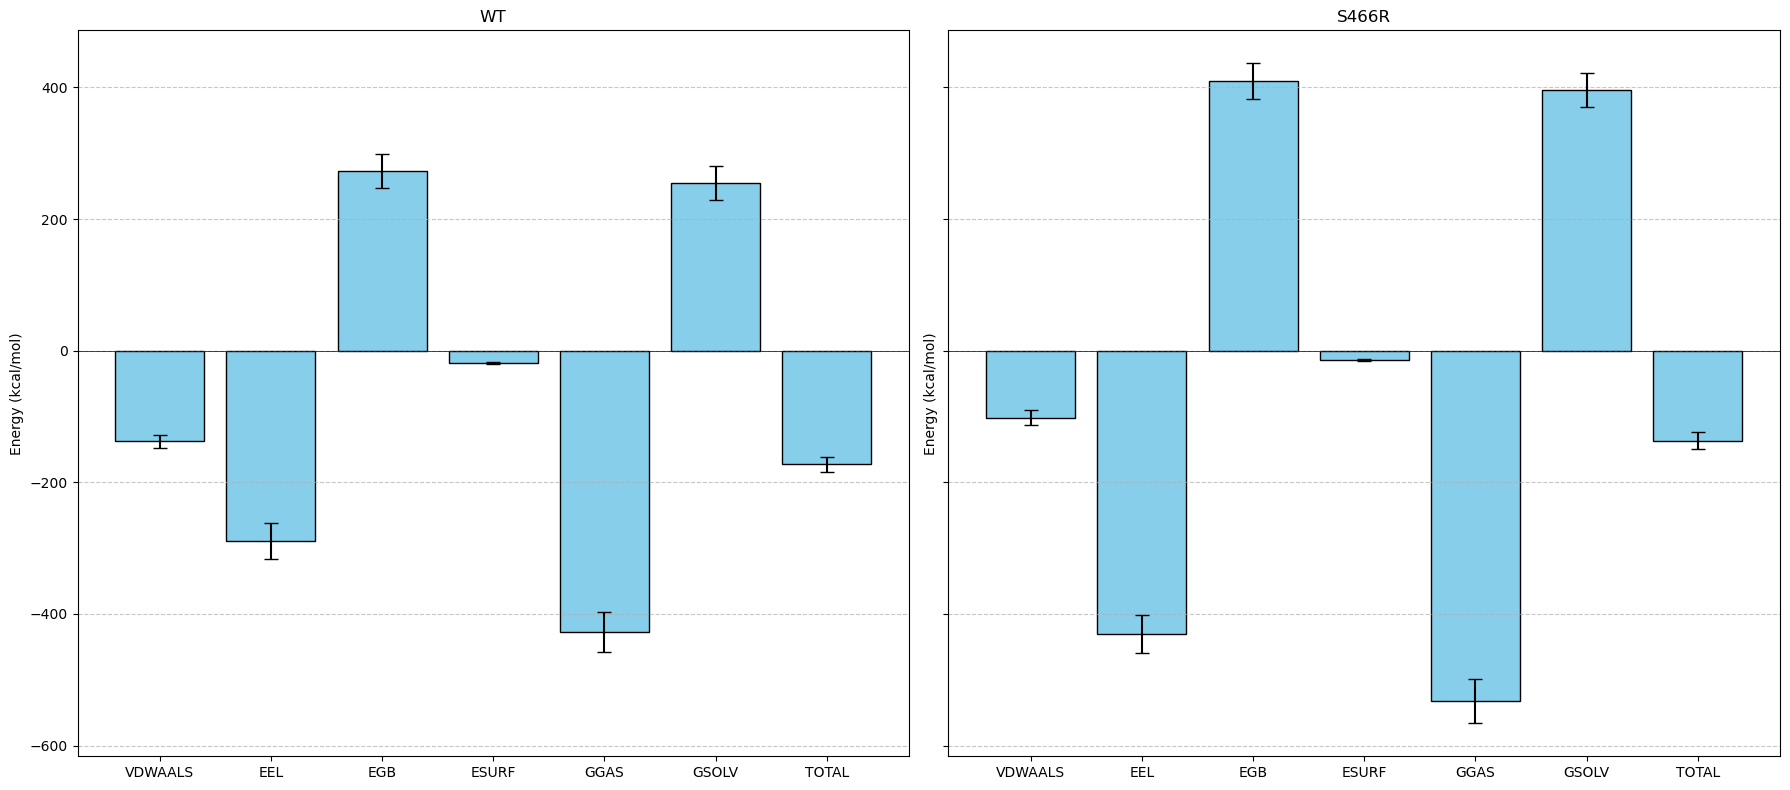

In [17]:

# Find global min and max
all_data = [
    wt_combined_df.transpose().values,
    S466R_combined_df.transpose().values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True, sharex=True)
ax1, ax2 = axes.flatten()

plots = [
    (wt_combined_df.transpose(), ax1, 'WT'),
    (S466R_combined_df.transpose(), ax2, 'S466R'),
]

for df, ax, title in plots:
    ax.bar(df.index, df['mean'], yerr=df['std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)


plt.tight_layout()
plt.show()

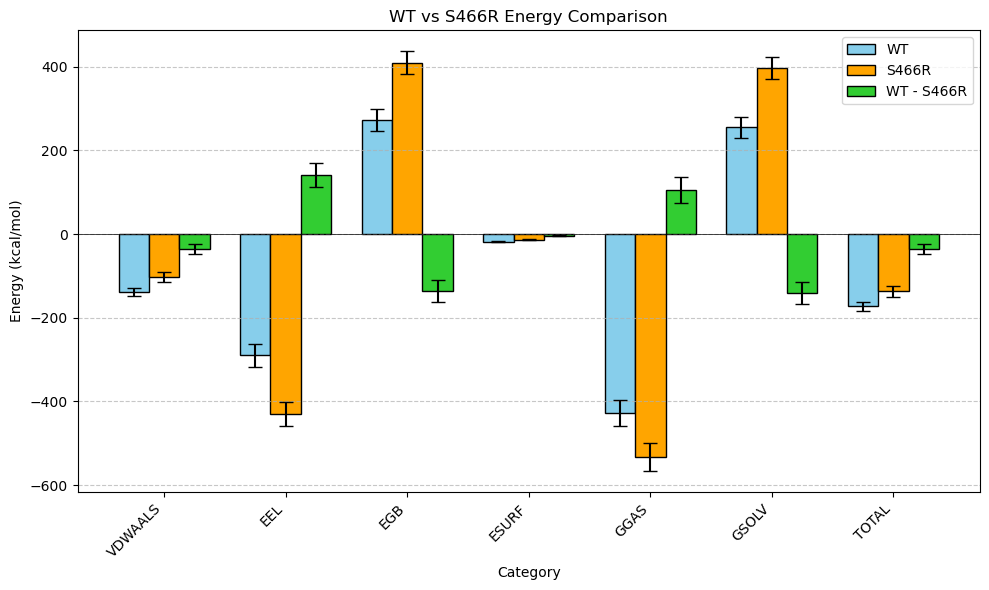

In [18]:
wt_combined_df_t = wt_combined_df.transpose()
S466R_combined_df_t = S466R_combined_df.transpose()

# Find global min and max 
all_data = [
    wt_combined_df_t.values,
    S466R_combined_df_t.values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

# Verify that dfs have the same index
if not wt_combined_df_t.index.equals(S466R_combined_df_t.index):
    raise ValueError("Indices of wt_combined_df_t and S466R_combined_df_t do not match!")


diff_df = pd.DataFrame({
    'mean': wt_combined_df_t['mean'] - S466R_combined_df_t['mean'],
    'std': np.sqrt((wt_combined_df_t['std']**2 + S466R_combined_df_t['std']**2) / 2)  # Pooled standard deviation
}, index=wt_combined_df_t.index)

fig, ax = plt.subplots(figsize=(10, 6))

labels = wt_combined_df_t.index  
x = np.arange(len(labels))  # Positions for bar groups
width = 0.25

# Plot WT bars
ax.bar(x - width, wt_combined_df_t['mean'], width, yerr=wt_combined_df_t['std'], 
       capsize=5, color='skyblue', edgecolor='black', label='WT')

# Plot S466R bars
ax.bar(x, S466R_combined_df_t['mean'], width, yerr=S466R_combined_df_t['std'], 
       capsize=5, color='orange', edgecolor='black', label='S466R')

# Plot difference (WT - S466R) bars
ax.bar(x + width, diff_df['mean'], width, yerr=diff_df['std'], 
       capsize=5, color='limegreen', edgecolor='black', label='WT - S466R')

ax.set_title('WT vs S466R Energy Comparison')
ax.set_xlabel('Category')
ax.set_ylabel('Energy (kcal/mol)')
ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=45, ha='right')
ax.grid(True, axis='y', linestyle='--', alpha=0.7)
ax.axhline(0, color='black', linewidth=0.5)
ax.legend()

plt.tight_layout()

In [19]:
table_df = pd.DataFrame({
    'Category': wt_combined_df_t.index,
    'WT Mean (kcal/mol)': wt_combined_df_t['mean'].round(2),
    'WT Std (kcal/mol)': wt_combined_df_t['std'].round(2),
    'S466R Mean (kcal/mol)': S466R_combined_df_t['mean'].round(2),
    'S466R Std (kcal/mol)': S466R_combined_df_t['std'].round(2),
    'Difference Mean (kcal/mol)': diff_df['mean'].round(2),
    'Difference Std (kcal/mol)': diff_df['std'].round(2)
})

# Generate LaTeX table rows
latex_rows = []
for _, row in table_df.iterrows():
    latex_rows.append(
        f"{row['Category']} & {row['WT Mean (kcal/mol)']} & {row['WT Std (kcal/mol)']} & "
        f"{row['S466R Mean (kcal/mol)']} & {row['S466R Std (kcal/mol)']} & "
        f"{row['Difference Mean (kcal/mol)']} & {row['Difference Std (kcal/mol)']} \\\\"
    )

# Print LaTeX table rows to copy into Overleaf
print("\n".join(latex_rows))
table_df

VDWAALS & -137.77 & 9.98 & -102.0 & 11.6 & -35.77 & 10.82 \\
EEL & -289.57 & 27.28 & -430.65 & 28.45 & 141.08 & 27.87 \\
EGB & 273.13 & 25.75 & 409.79 & 26.86 & -136.67 & 26.31 \\
ESURF & -18.37 & 1.3 & -13.94 & 1.42 & -4.42 & 1.36 \\
GGAS & -427.34 & 30.62 & -532.64 & 33.45 & 105.31 & 32.07 \\
GSOLV & 254.76 & 25.19 & 395.85 & 26.28 & -141.09 & 25.74 \\
TOTAL & -172.58 & 11.03 & -136.79 & 13.06 & -35.78 & 12.09 \\


,Category,WT Mean (kcal/mol),WT Std (kcal/mol),S466R Mean (kcal/mol),S466R Std (kcal/mol),Difference Mean (kcal/mol),Difference Std (kcal/mol)
VDWAALS,VDWAALS,-137.77,9.98,-102.00,11.60,-35.77,10.82
EEL,EEL,-289.57,27.28,-430.65,28.45,141.08,27.87
EGB,EGB,273.13,25.75,409.79,26.86,-136.67,26.31
ESURF,ESURF,-18.37,1.30,-13.94,1.42,-4.42,1.36
GGAS,GGAS,-427.34,30.62,-532.64,33.45,105.31,32.07
GSOLV,GSOLV,254.76,25.19,395.85,26.28,-141.09,25.74
TOTAL,TOTAL,-172.58,11.03,-136.79,13.06,-35.78,12.09


In [20]:
wt_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-137.768796,-289.567532,273.126104,-18.365023,-427.336244,254.760951,-172.575176
std,9.984252,27.278466,25.747698,1.298792,30.623010,25.194886,11.030096


In [21]:
S466R_combined_df

,VDWAALS,EEL,EGB,ESURF,GGAS,GSOLV,TOTAL
mean,-101.997738,-430.647335,409.794661,-13.943759,-532.644943,395.850825,-136.794198
std,11.599513,28.447880,26.857063,1.420522,33.450938,26.275034,13.059109


In [22]:
diff_df

,mean,std
VDWAALS,-35.771058,10.822061
EEL,141.079804,27.869307
EGB,-136.668556,26.308229
ESURF,-4.421264,1.361019
GGAS,105.308699,32.068161
GSOLV,-141.089874,25.740626
TOTAL,-35.780978,12.087253


#### Interpretation


## Residue decomposition

### Load data

In [23]:
def load_decompenergy(mut):
    dfs = []
    for rep in range(1, 4):
        energyfile = f'../../data/1bf5/{mut}/rep{rep}/analysis/006_gbsa_8A/FINAL_ENERGY_DECOMP.csv'
        with open(energyfile, 'r') as f:
            lines = f.readlines()

        # Find the start and end indices for the section
        start_idx = None
        end_idx = None
        for i, line in enumerate(lines):
            line_clean = line.strip()
            if "DELTAS:" in line_clean:
                start_idx = i + 2  # Skip "DELTAS:" and "Total Decomposition Contribution (TDC)"
                continue
            if start_idx is not None and "Sidechain Decomposition Contribution" in line_clean:
                end_idx = i  
                break

        # Extract the lines between start_idx and end_idx
        data_lines = lines[start_idx:end_idx]
        data_string = ''.join(data_lines)

        df = pd.read_csv(StringIO(data_string))
        dfs.append(df)

    return dfs

In [24]:
wt_decomp_dfs = load_decompenergy('wt')
S466R_decomp_dfs = load_decompenergy('S466R')

In [25]:
wt_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,L:A:CYS:189,0.0,-0.03,-0.24,0.23,0.00,-0.04
1,1000,L:A:MET:190,0.0,-0.36,-0.97,0.92,-0.02,-0.44
2,1000,L:A:PRO:191,0.0,-0.29,-0.50,0.48,-0.02,-0.32
3,1000,L:A:THR:192,0.0,-1.20,-0.89,0.56,-0.52,-2.05
4,1000,L:A:HIE:193,0.0,-0.26,-0.82,0.82,0.00,-0.27


In [26]:
S466R_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL
0,1000,L:A:MET:190,0.0,-0.06,0.21,-0.19,0.00,-0.05
1,1000,L:A:PRO:191,0.0,-0.22,0.21,-0.17,-0.01,-0.19
2,1000,L:A:THR:192,0.0,-0.47,0.87,-0.75,-0.15,-0.49
3,1000,L:A:HIE:193,0.0,-0.17,-0.56,0.57,0.00,-0.16
4,1000,L:A:LEU:200,0.0,-0.04,0.06,-0.05,0.00,-0.03


Break down the residue identifiers and adjust the residue numbers.

In [27]:
for df in (wt_decomp_dfs + S466R_decomp_dfs):
    split_cols = df["Residue"].str.split(":", expand=True)
    df["compound"] = split_cols[0]
    df["chain"] = split_cols[1]
    df["resnm"] = split_cols[2]
    df["resid"] = split_cols[3]
    df["resid_adj"] = np.where(df["chain"].isin(["A", "B"]), (df['resid'].astype(int)+ 135).astype(str), df['resid'])


In [28]:
wt_decomp_dfs[0].head()

,Frame #,Residue,Internal,van der Waals,Electrostatic,Polar Solvation,Non-Polar Solv.,TOTAL,compound,chain,resnm,resid,resid_adj
0,1000,L:A:CYS:189,0.0,-0.03,-0.24,0.23,0.00,-0.04,L,A,CYS,189,324
1,1000,L:A:MET:190,0.0,-0.36,-0.97,0.92,-0.02,-0.44,L,A,MET,190,325
2,1000,L:A:PRO:191,0.0,-0.29,-0.50,0.48,-0.02,-0.32,L,A,PRO,191,326
3,1000,L:A:THR:192,0.0,-1.20,-0.89,0.56,-0.52,-2.05,L,A,THR,192,327
4,1000,L:A:HIE:193,0.0,-0.26,-0.82,0.82,0.00,-0.27,L,A,HIE,193,328


### By replicate

In [29]:
def decomp_summary (dfs):
    dfs_decomp_summary = []

    # Energy columns to summarize
    energy_columns = ['van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]

    for df in dfs:
        # Group by residue identifiers
        grouped = df.groupby(['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj'])
        
        # Compute mean, std, and sem for energy columns
        desc = pd.concat([
            grouped[energy_columns].mean().rename(columns=lambda x: f'{x}_mean'),
            grouped[energy_columns].std().rename(columns=lambda x: f'{x}_std'),
        ], axis=1)
        
        # Reset index to make Residue, compound, chain, resnm, resid regular columns
        desc = desc.reset_index()
        
        # Append to summary list
        dfs_decomp_summary.append(desc)
    return dfs_decomp_summary

In [30]:
wt_decomp_summary = decomp_summary(wt_decomp_dfs)
S466R_decomp_summary = decomp_summary(S466R_decomp_dfs)

In [31]:
wt_decomp_summary[0].head()

,Residue,compound,chain,resnm,resid,resid_adj,van der Waals_mean,Electrostatic_mean,Polar Solvation_mean,Non-Polar Solv._mean,TOTAL_mean,van der Waals_std,Electrostatic_std,Polar Solvation_std,Non-Polar Solv._std,TOTAL_std
0,L:A:ALA:280,L,A,ALA,280,415,-0.017146,-0.018273,0.019800,0.000000,-0.015319,0.010767,0.321305,0.303911,0.000000,0.022415
1,L:A:ARG:243,L,A,ARG,243,378,-0.812884,-33.997984,32.926407,-0.118253,-2.002874,0.551134,0.639254,0.540212,0.030703,0.507411
2,L:A:ARG:270,L,A,ARG,270,405,-0.099092,-28.695439,28.183593,-0.008154,-0.619222,0.073191,1.996519,1.876289,0.030063,0.206793
3,L:A:ARG:283,L,A,ARG,283,418,-0.357176,-28.120120,27.481786,-0.140250,-1.135699,0.632486,4.142819,3.857355,0.187710,0.905507
4,L:A:ASN:246,L,A,ASN,246,381,-0.020409,0.115160,-0.102814,0.000000,-0.008144,0.003757,0.313016,0.297232,0.000000,0.017060


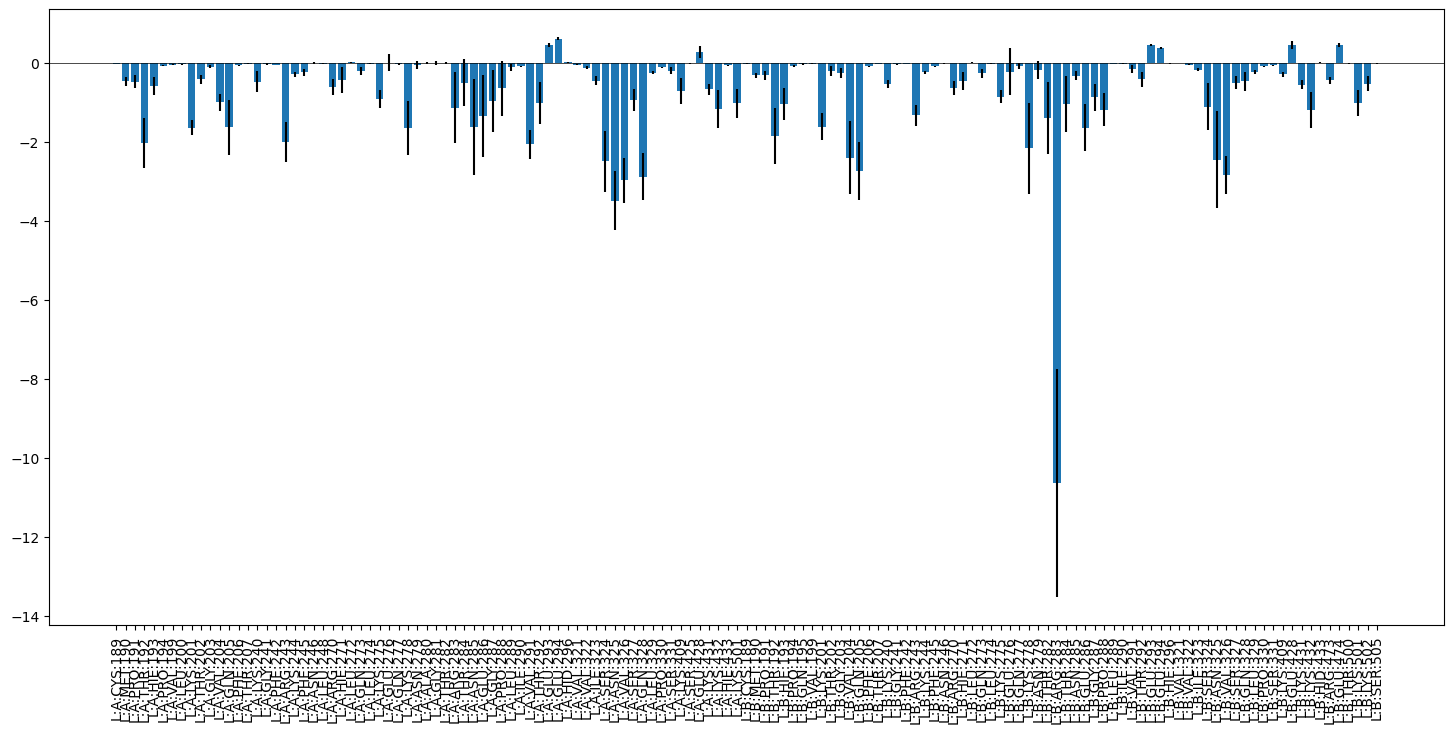

In [32]:
df = wt_decomp_summary[0][wt_decomp_summary[0]["compound"] == "L"].sort_values(by=["chain", "resid"], ascending=True)
plt.figure(figsize=(18, 8))
plt.bar(df['Residue'], df['TOTAL_mean'], yerr=df['TOTAL_std'])

plt.axhline(0, color='black', linewidth=0.5)
plt.xticks(rotation=90)
plt.show()

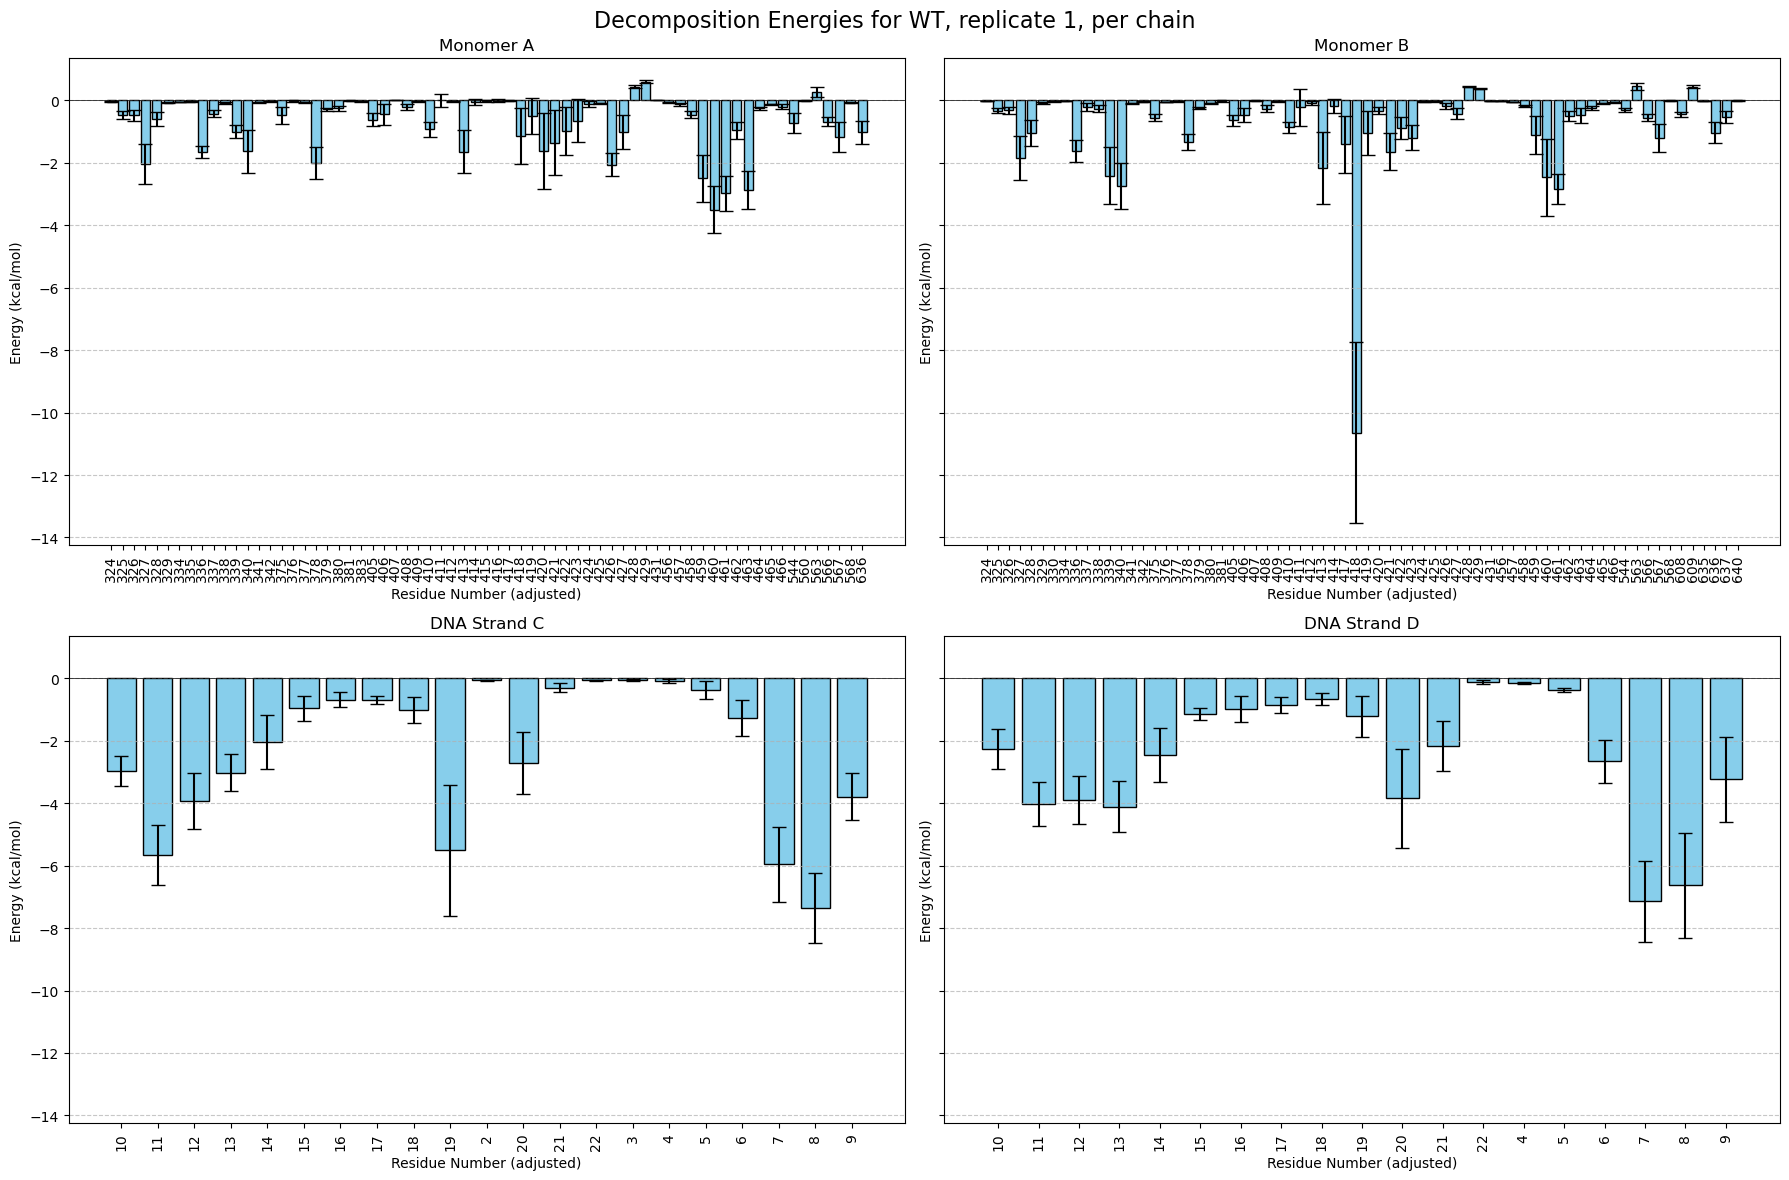

In [33]:
df_chainA = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_chainB = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_chainC = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_chainD = wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)


# Find global min and max
all_data = [
    df_chainA['TOTAL_mean'].values,
    df_chainB['TOTAL_mean'].values,
    df_chainC['TOTAL_mean'].values,
    df_chainD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_chainA, ax1, 'Monomer A'),
    (df_chainB, ax2, 'Monomer B'),
    (df_chainC, ax3, 'DNA Strand C'),
    (df_chainD, ax4, 'DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df["resid_adj"], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

In [34]:
wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "A"].sort_values('resid_adj')['resid_adj'].unique() 

array(['324', '325', '326', '327', '328', '329', '334', '335', '336',
       '337', '338', '339', '340', '341', '342', '375', '376', '377',
       '378', '379', '380', '381', '383', '405', '406', '407', '408',
       '409', '410', '411', '412', '413', '414', '415', '416', '417',
       '418', '419', '420', '421', '422', '423', '424', '425', '426',
       '427', '428', '429', '431', '456', '457', '458', '459', '460',
       '461', '462', '463', '464', '465', '466', '544', '560', '563',
       '566', '567', '568', '636'], dtype=object)

In [37]:
wt_decomp_summary[0][wt_decomp_summary[0]["chain"] == "B"].sort_values('resid_adj')['resid_adj'].unique() 

array(['324', '325', '326', '327', '328', '329', '330', '334', '336',
       '337', '338', '339', '340', '341', '342', '375', '376', '377',
       '378', '379', '380', '381', '405', '406', '407', '408', '409',
       '410', '411', '412', '413', '414', '417', '418', '419', '420',
       '421', '422', '423', '424', '425', '426', '427', '428', '429',
       '431', '456', '457', '458', '459', '460', '461', '462', '463',
       '464', '465', '466', '544', '563', '566', '567', '568', '608',
       '609', '635', '636', '637', '640'], dtype=object)

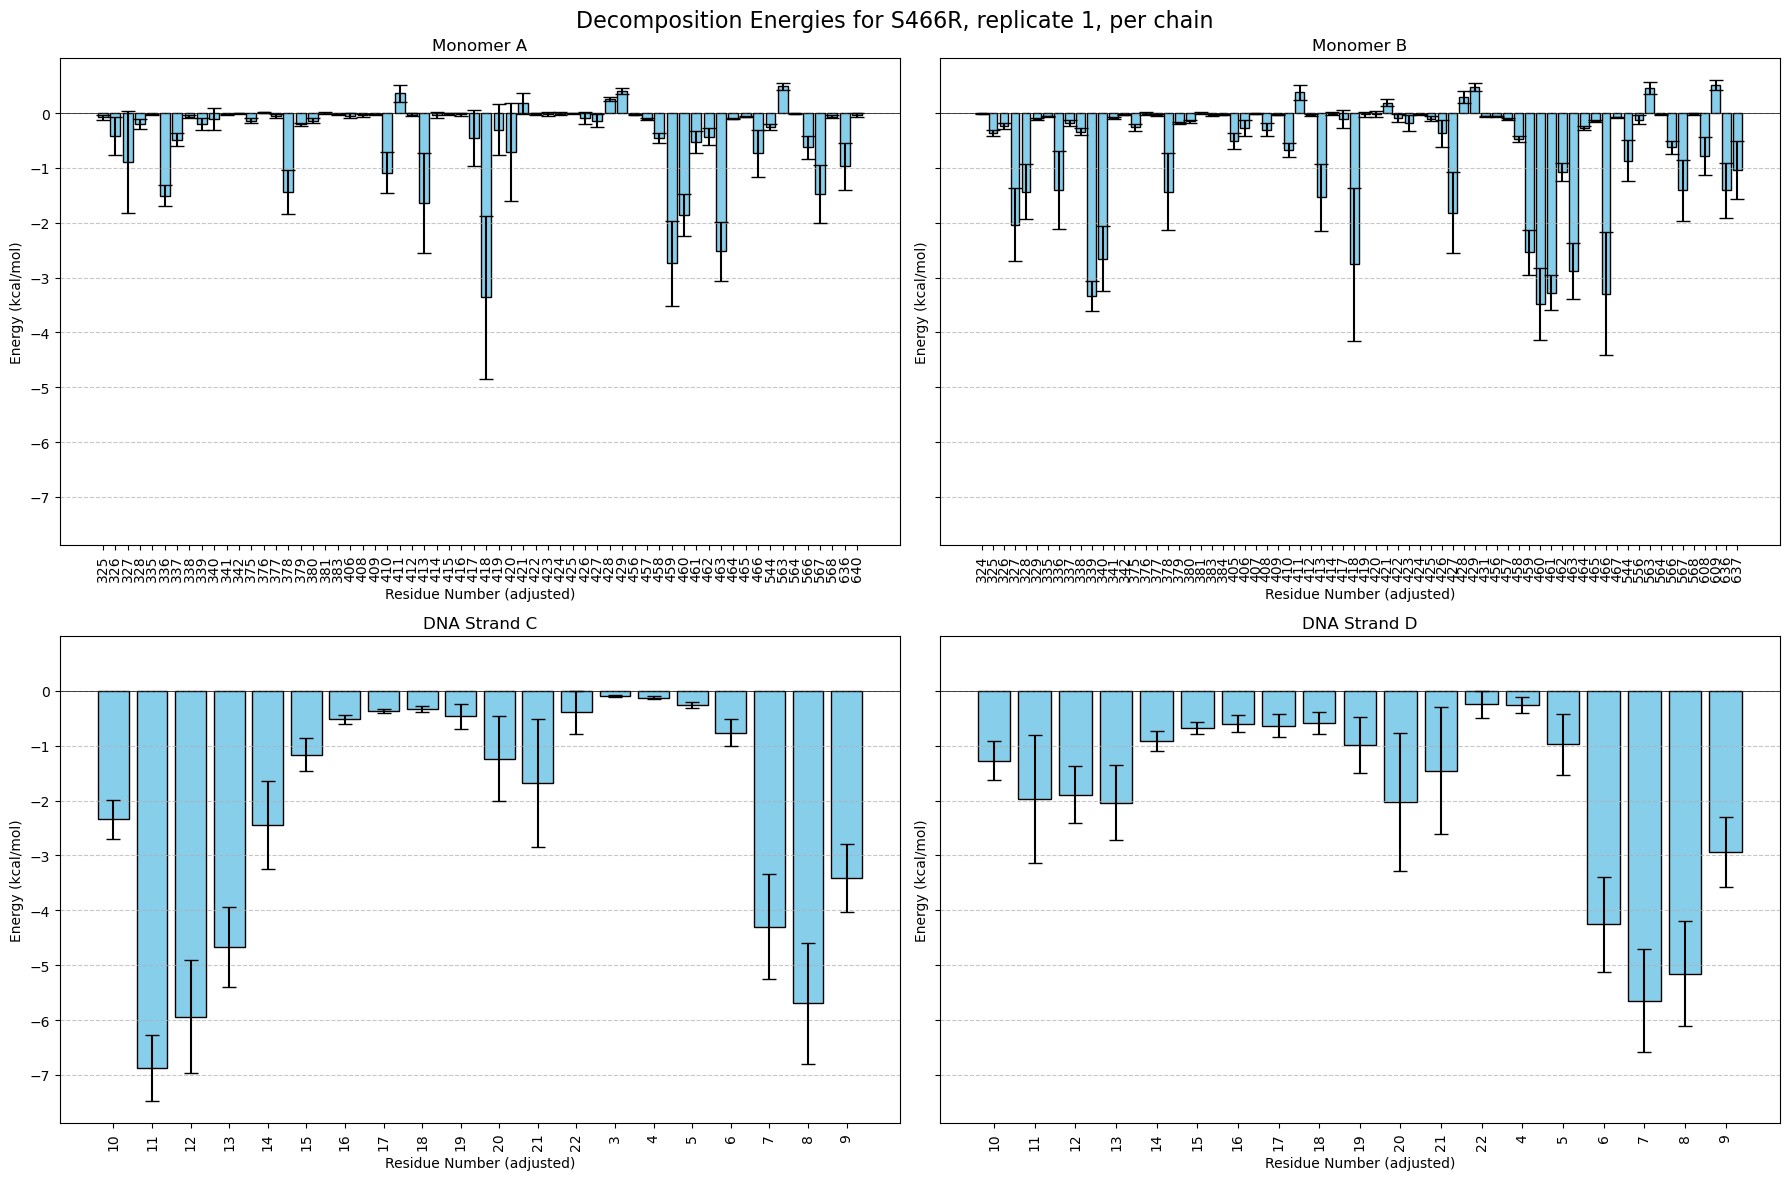

In [38]:

df_chainA = S466R_decomp_summary[0][S466R_decomp_summary[0]["chain"] == "A"].sort_values(by=["resid"], ascending=True)
df_chainB = S466R_decomp_summary[0][S466R_decomp_summary[0]["chain"] == "B"].sort_values(by=["resid"], ascending=True)
df_chainC = S466R_decomp_summary[0][S466R_decomp_summary[0]["chain"] == "C"].sort_values(by=["resid"], ascending=True)
df_chainD = S466R_decomp_summary[0][S466R_decomp_summary[0]["chain"] == "D"].sort_values(by=["resid"], ascending=True)


# Find global min and max
all_data = [
    df_chainA['TOTAL_mean'].values,
    df_chainB['TOTAL_mean'].values,
    df_chainC['TOTAL_mean'].values,
    df_chainD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_chainA, ax1, 'Monomer A'),
    (df_chainB, ax2, 'Monomer B'),
    (df_chainC, ax3, 'DNA Strand C'),
    (df_chainD, ax4, 'DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for S466R, replicate 1, per chain', fontsize=16)

plt.tight_layout()
plt.show()

There might be significant differences between monomers for corresponding residues, that is, residues with the same number. Also note that MMPBSA filtered out different residues in each monomer, likely due to their energy values close to zero. 
It is challenging to draw conclusions from the separate replicate data and it is advisable to aggregate it.

### By mutation (combining replicates)

In [39]:
def combine_decomp(dfs):
    
    df = pd.concat(dfs)

    energy_terms = ['van der Waals', 'Electrostatic', 
        'Polar Solvation', 'Non-Polar Solv.', 'TOTAL'
    ]
    
    # Columns for means and standard deviations
    mean_cols = [f"{term}_mean" for term in energy_terms]
    std_cols = [f"{term}_std" for term in energy_terms]
    
    # Group by residue identifiers
    group_cols = ['Residue', 'compound', 'chain', 'resnm', 'resid', 'resid_adj']
    df_grouped = df.groupby(group_cols)
    
    result_data = []
    
    # Process each group (residue)
    for name, group in df_grouped:
        # Dictionary to store results for this group
        group_result = dict(zip(group_cols, name))
        
        # Calculate mean and pooled std for each energy term
        for mean_col, std_col in zip(mean_cols, std_cols):
            # Mean
            combined_mean = group[mean_col].mean()
            
            # Pooled standard deviation
            stds = group[std_col]
            variances = [s**2 for s in stds]
            pooled_variance = np.mean(variances)  # Average variances
            pooled_std = np.sqrt(pooled_variance) if pooled_variance > 0 else 0.0
            
            group_result[mean_col] = combined_mean
            group_result[std_col] = pooled_std
        
        result_data.append(group_result)
    
    combined_df = pd.DataFrame(result_data)
    
    # Reorder columns to match input structure
    output_cols = group_cols + [col for term in energy_terms for col in [f"{term}_mean", f"{term}_std"]]
    combined_df = combined_df[output_cols]
    
    return combined_df

In [40]:
wt_decomp_combined_df = combine_decomp(wt_decomp_summary)
S466R_decomp_combined_df = combine_decomp(S466R_decomp_summary)

In [41]:
wt_decomp_combined_df.head()

,Residue,compound,chain,resnm,resid,resid_adj,van der Waals_mean,van der Waals_std,Electrostatic_mean,Electrostatic_std,Polar Solvation_mean,Polar Solvation_std,Non-Polar Solv._mean,Non-Polar Solv._std,TOTAL_mean,TOTAL_std
0,L:A:ALA:280,L,A,ALA,280,415,-0.041045,0.042450,-0.042901,0.321611,0.045269,0.301987,-0.001015,0.009188,-0.039594,0.053684
1,L:A:ARG:196,L,A,ARG,196,331,-0.023693,0.006332,-25.373513,0.631378,25.069501,0.604957,0.000000,0.000000,-0.327754,0.032156
2,L:A:ARG:243,L,A,ARG,243,378,-0.780729,0.564764,-33.489541,0.633727,32.407764,0.549420,-0.135542,0.034170,-1.998114,0.521936
3,L:A:ARG:270,L,A,ARG,270,405,-0.053786,0.048435,-26.123407,1.672737,25.746544,1.580436,-0.003896,0.020108,-0.434481,0.149108
4,L:A:ARG:283,L,A,ARG,283,418,-1.408623,1.126137,-28.401906,3.768551,27.720366,3.498618,-0.309102,0.238257,-2.399155,1.443181


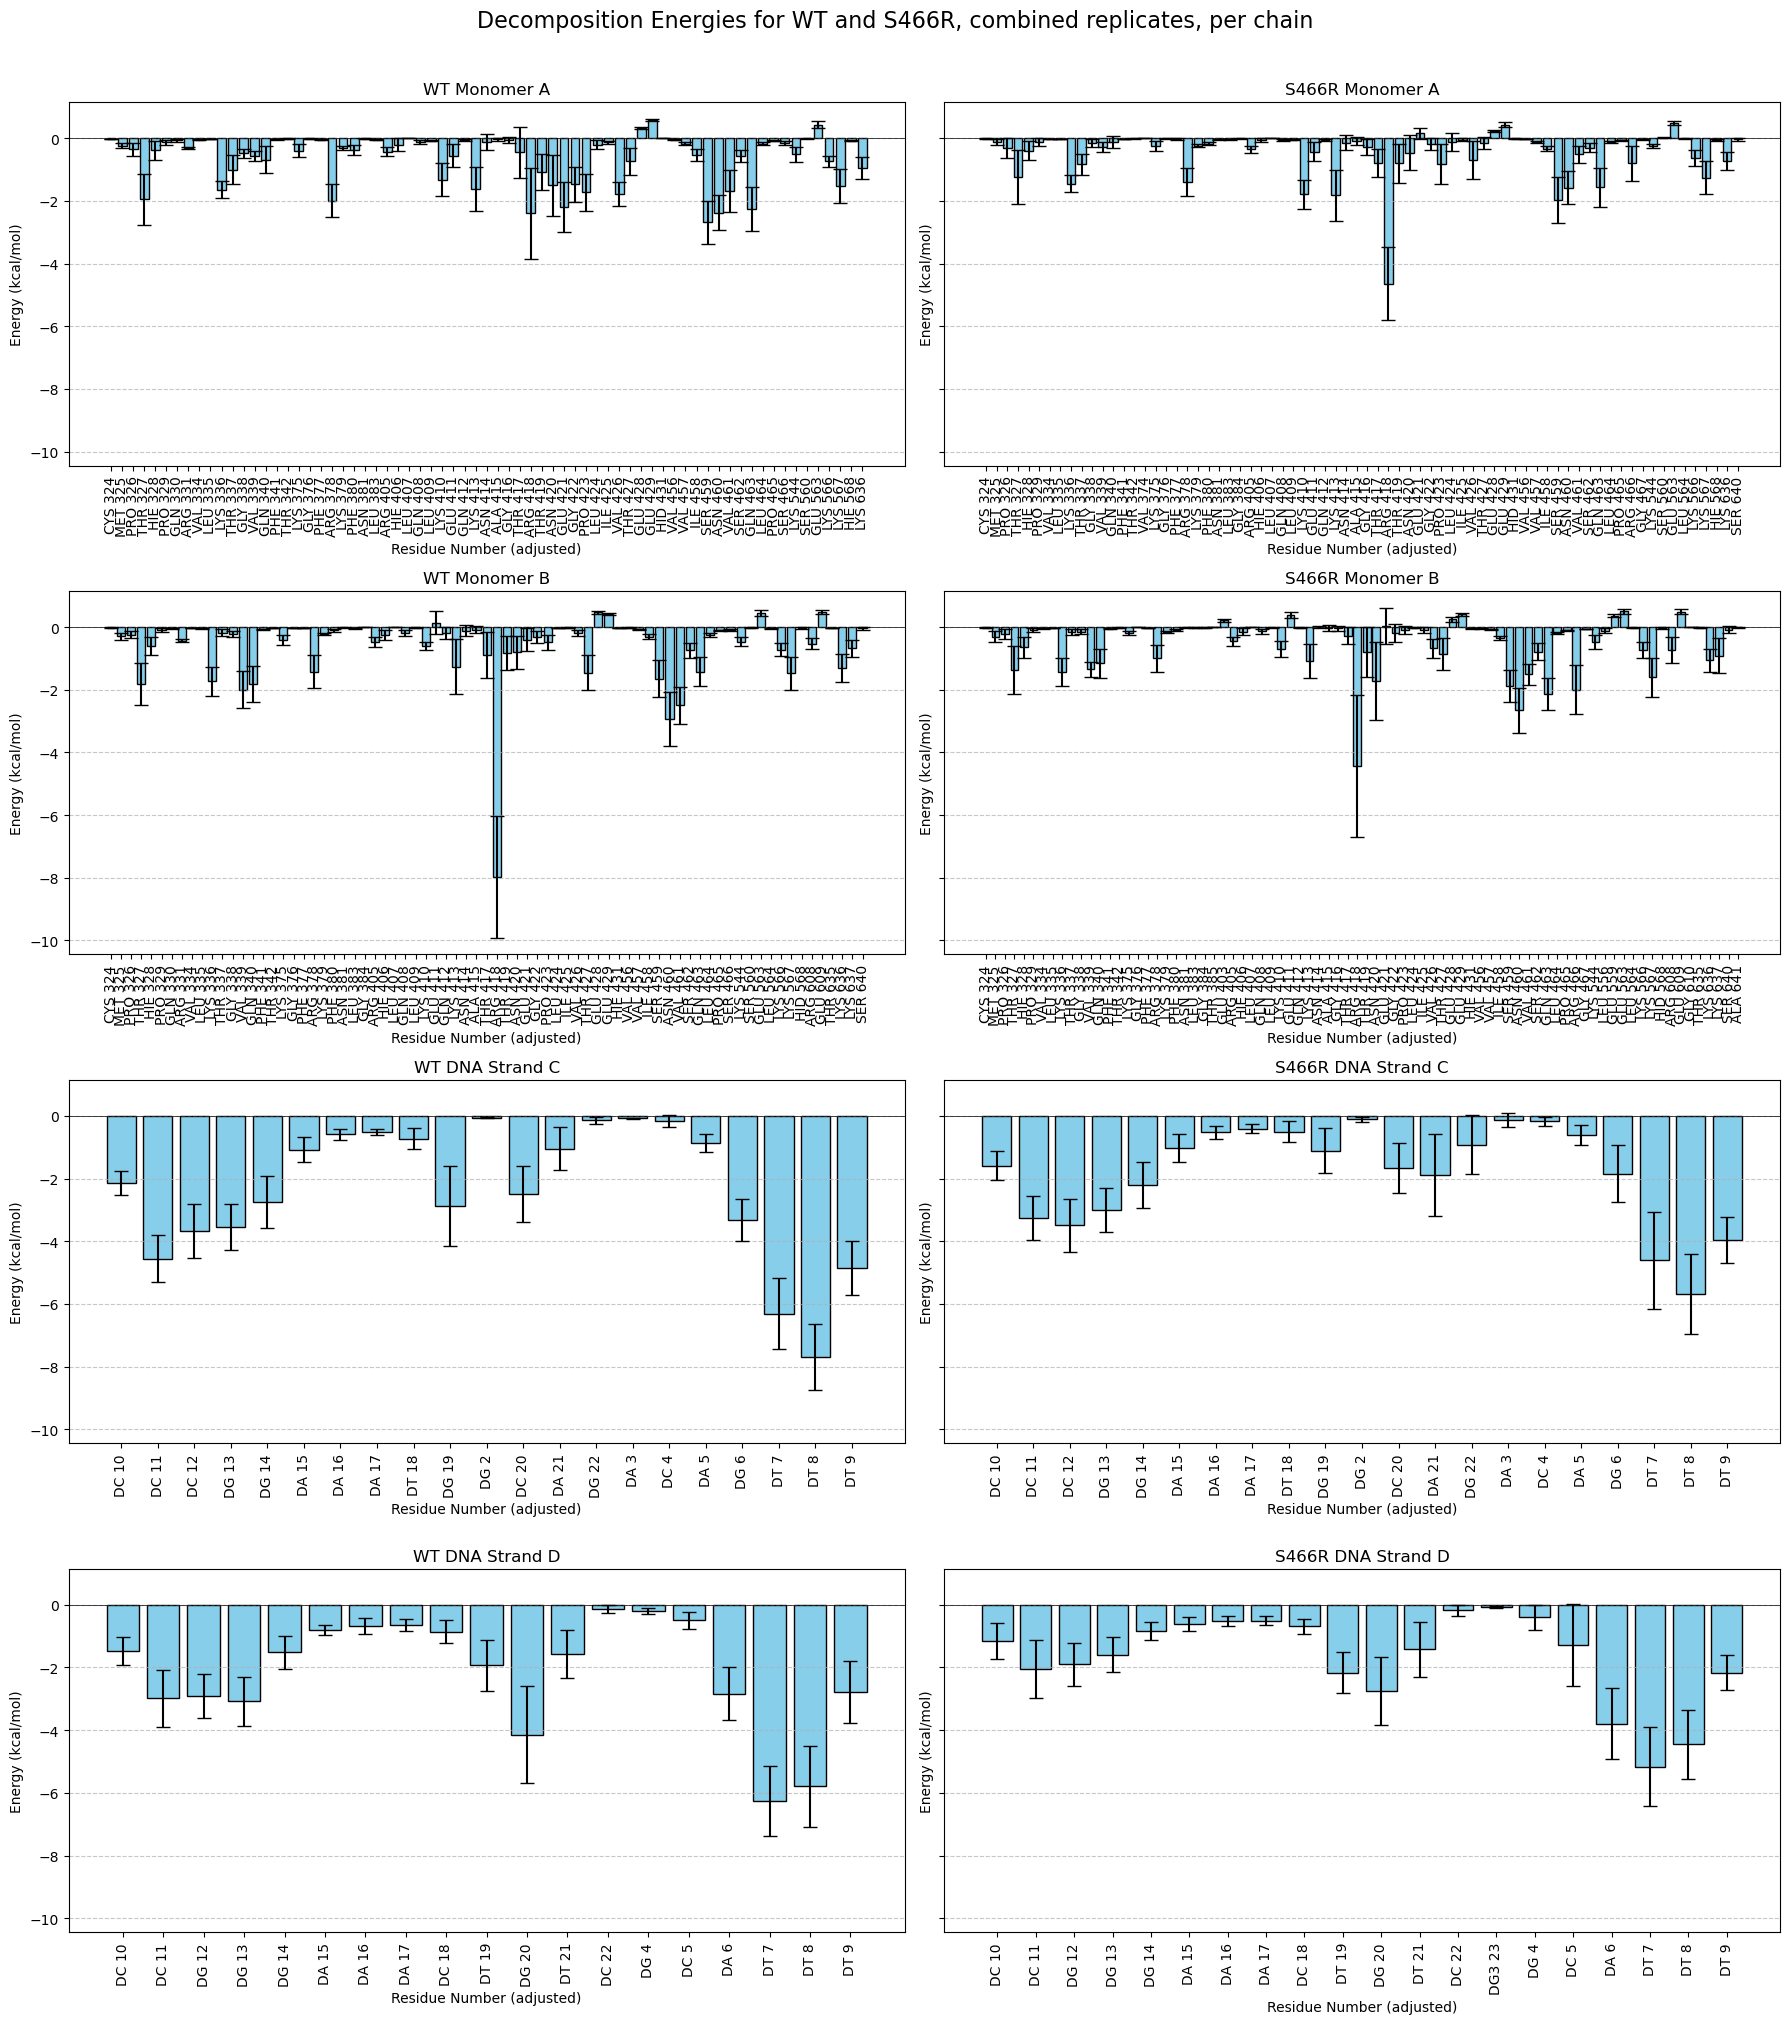

In [42]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoA = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoB = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaC = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_dnaC = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaD = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_dnaD = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)

# Find global min and max
all_data = [
    df_wt_monoA['TOTAL_mean'].values,
    df_S466R_monoA['TOTAL_mean'].values,
    df_wt_monoB['TOTAL_mean'].values,
    df_S466R_monoB['TOTAL_mean'].values,
    df_wt_dnaC['TOTAL_mean'].values,
    df_S466R_dnaC['TOTAL_mean'].values,
    df_wt_dnaD['TOTAL_mean'].values,
    df_S466R_dnaD['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(4, 2, figsize=(18, 20), sharey=True)
ax1, ax2, ax3, ax4, ax5, ax6, ax7, ax8 = axes.flatten()

plots = [
    (df_wt_monoA, ax1, 'WT Monomer A'),
    (df_S466R_monoA, ax2, 'S466R Monomer A'),
    (df_wt_monoB, ax3, 'WT Monomer B'),
    (df_S466R_monoB, ax4, 'S466R Monomer B'),
    (df_wt_dnaC, ax5, 'WT DNA Strand C'),   
    (df_S466R_dnaC, ax6, 'S466R DNA Strand C'),
    (df_wt_dnaD, ax7, 'WT DNA Strand D'),
    (df_S466R_dnaD, ax8, 'S466R DNA Strand D'),
]

for df, ax, title in plots:
    ax.bar(df['resid_adj'], df['TOTAL_mean'], yerr=df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(df['resnm'], df['resid_adj'])])
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and S466R, combined replicates, per chain', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

Zoom in on the mutated residue.

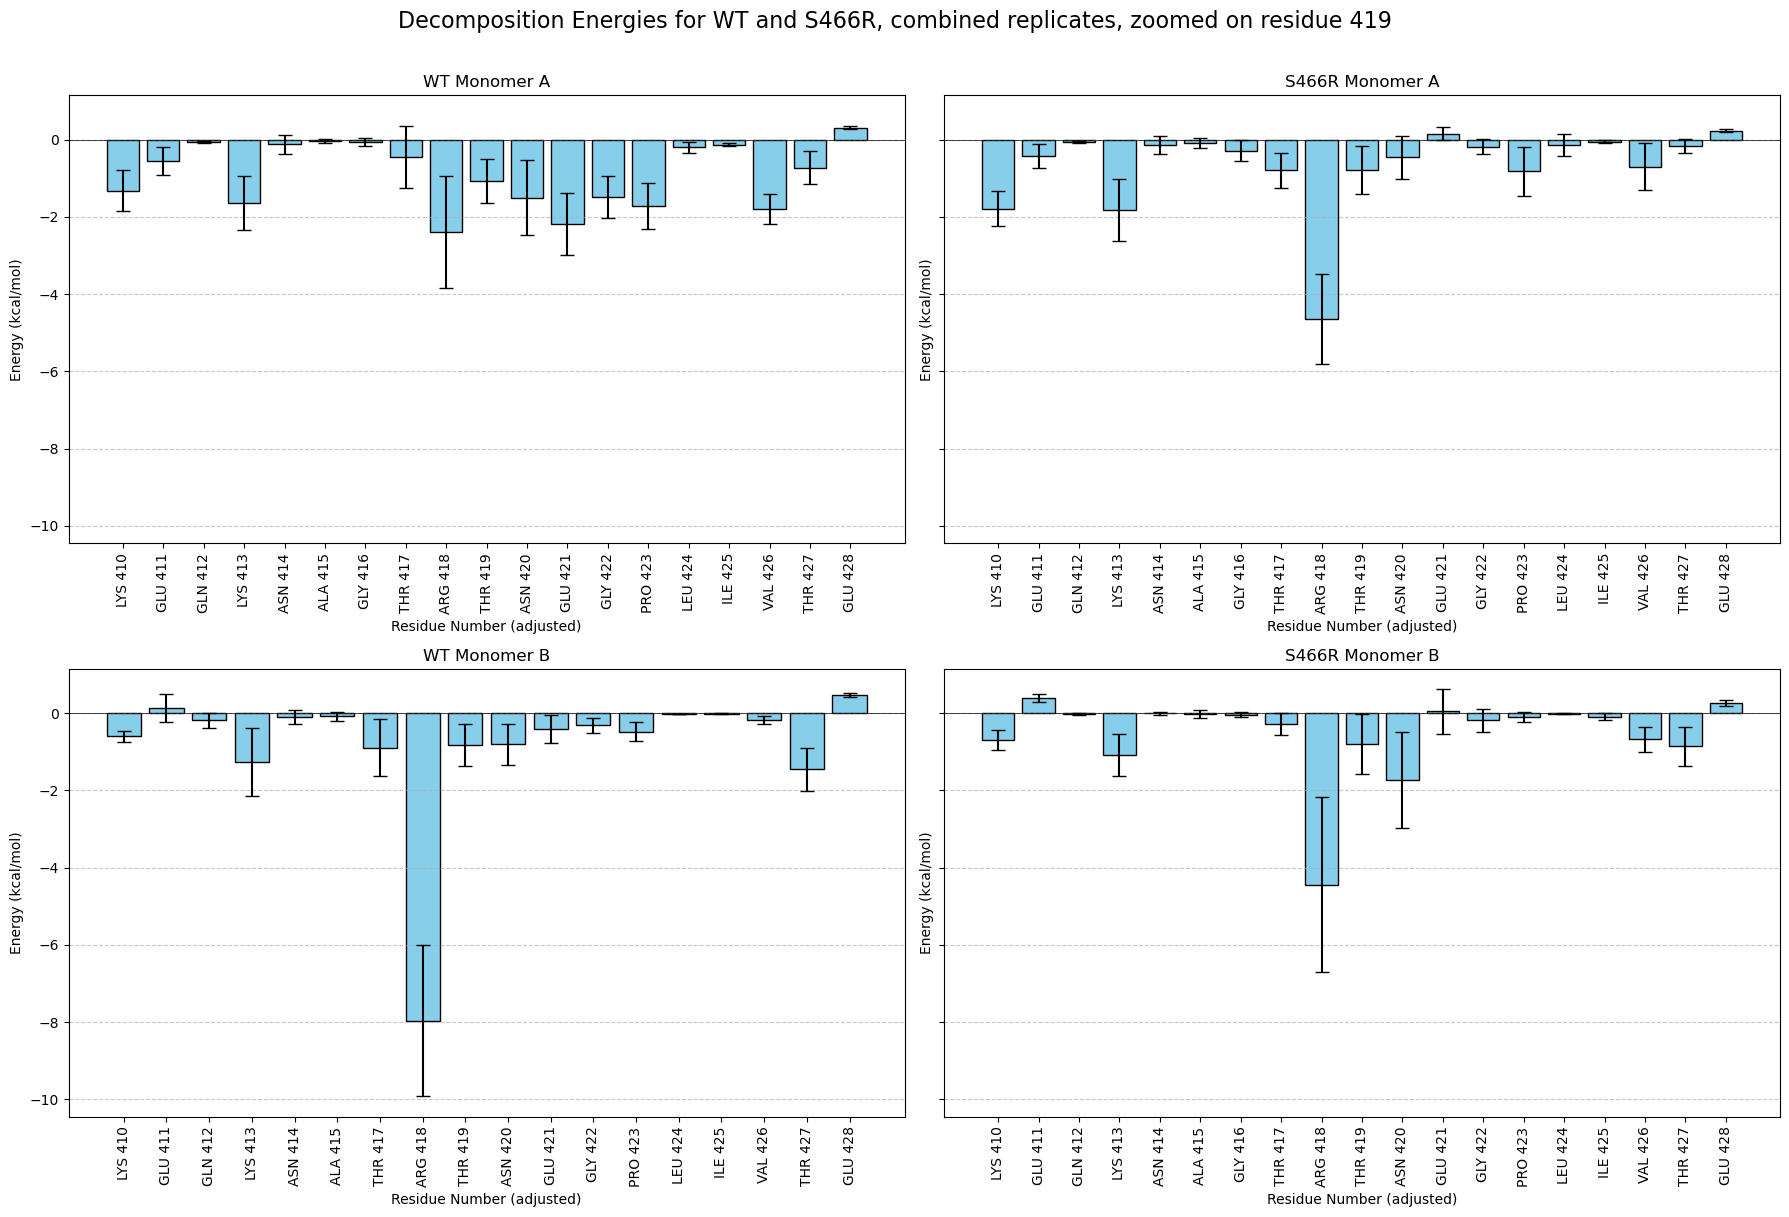

In [43]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoA = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoB = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

# Find global min and max
all_data = [
    df_wt_monoA['TOTAL_mean'].values,
    df_S466R_monoA['TOTAL_mean'].values,
    df_wt_monoB['TOTAL_mean'].values,
    df_S466R_monoB['TOTAL_mean'].values,
]
global_min = min([np.nanmin(data) for data in all_data])
global_max = max([np.nanmax(data) for data in all_data])

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_wt_monoA, ax1, 'WT Monomer A'),
    (df_S466R_monoA, ax2, 'S466R Monomer A'),
    (df_wt_monoB, ax3, 'WT Monomer B'),
    (df_S466R_monoB, ax4, 'S466R Monomer B'),
]

for df, ax, title in plots:
    filtered_df = df[(df['resid_adj'].astype(int) > 409) & (df['resid_adj'].astype(int) < 429)]
    ax.bar(filtered_df['resid_adj'], filtered_df['TOTAL_mean'], yerr=filtered_df['TOTAL_std'], capsize=5, color='skyblue', edgecolor='black')
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.tick_params(axis='x', rotation=90, labelbottom=True,)
    ax.set_xticks(filtered_df['resid_adj'])
    ax.set_xticklabels([f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])])
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)

plt.suptitle('Decomposition Energies for WT and S466R, combined replicates, zoomed on residue 419', fontsize=16, y=1.01)

plt.tight_layout()
plt.show()

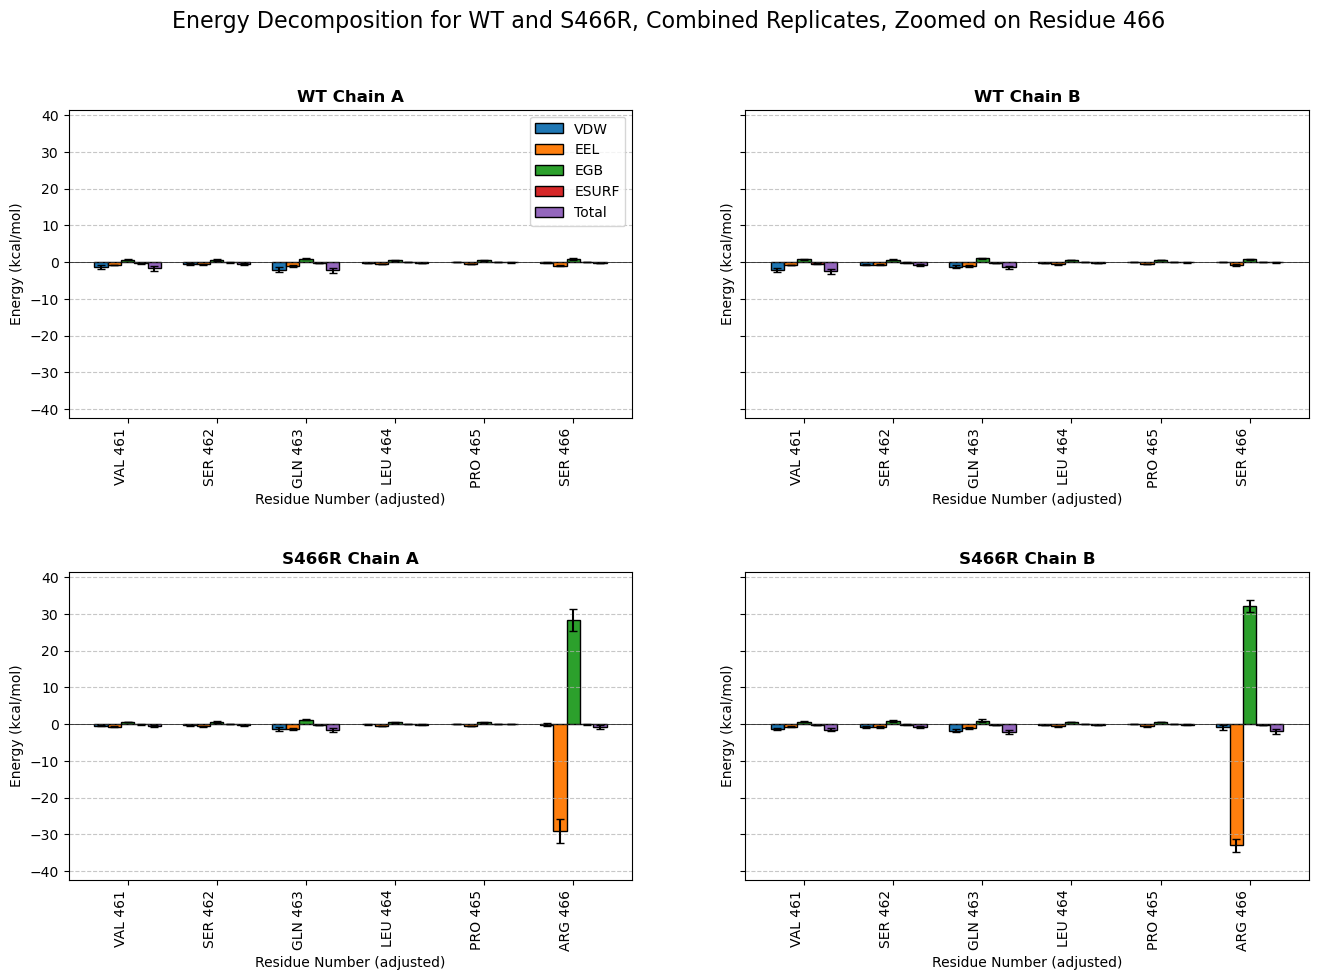

In [57]:
df_wt_monoA = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoA = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "A"].sort_values(by=["resid_adj"], ascending=True)

df_wt_monoB = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_monoB = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "B"].sort_values(by=["resid_adj"], ascending=True)

# Define energy terms and their corresponding std columns
energy_terms = [
    'van der Waals_mean', 'Electrostatic_mean', 'Polar Solvation_mean',
    'Non-Polar Solv._mean', 'TOTAL_mean'
]
std_terms = [
    'van der Waals_std', 'Electrostatic_std', 'Polar Solvation_std',
    'Non-Polar Solv._std', 'TOTAL_std'
]

# Find global min and max across all energy terms
all_data = []
for df in [df_wt_monoA, df_S466R_monoA, df_wt_monoB, df_S466R_monoB]:
    for term in energy_terms:
        all_data.append(df[term].values)
global_min = min([np.nanmin(data) for data in all_data]) * 1.1  # Add 10% buffer
global_max = max([np.nanmax(data) for data in all_data]) * 1.1  # Add 10% buffer

# Create figure and subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Define plots
plots = [
    (df_wt_monoA, ax1, 'WT Chain A'),
    (df_wt_monoB, ax2, 'WT Chain B'),
    (df_S466R_monoA, ax3, 'S466R Chain A'),
    (df_S466R_monoB, ax4, 'S466R Chain B'),
]

# Plotting parameters
n_terms = len(energy_terms)  # Number of energy terms (5)
bar_width = 0.15  # Width of each bar
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total']  # Short labels for legend

for df, ax, title in plots:
    # Filter for residues in the range 456-470
    filtered_df = df[(df['resid_adj'].astype(int) > 460) & (df['resid_adj'].astype(int) < 467)]
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        # Calculate x positions for this term's bars
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        # Plot bars with error bars
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label if ax == ax1 else None  # Add legend only on first subplot
        )
    
    # Customize axes
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)  # Set consistent y-limits

# Add legend to the first subplot
ax1.legend(loc='best')

# Add suptitle and adjust layout
plt.suptitle('Energy Decomposition for WT and S466R, Combined Replicates, Zoomed on Residue 466', fontsize=16)

plt.subplots_adjust(hspace=0.5)
plt.show()

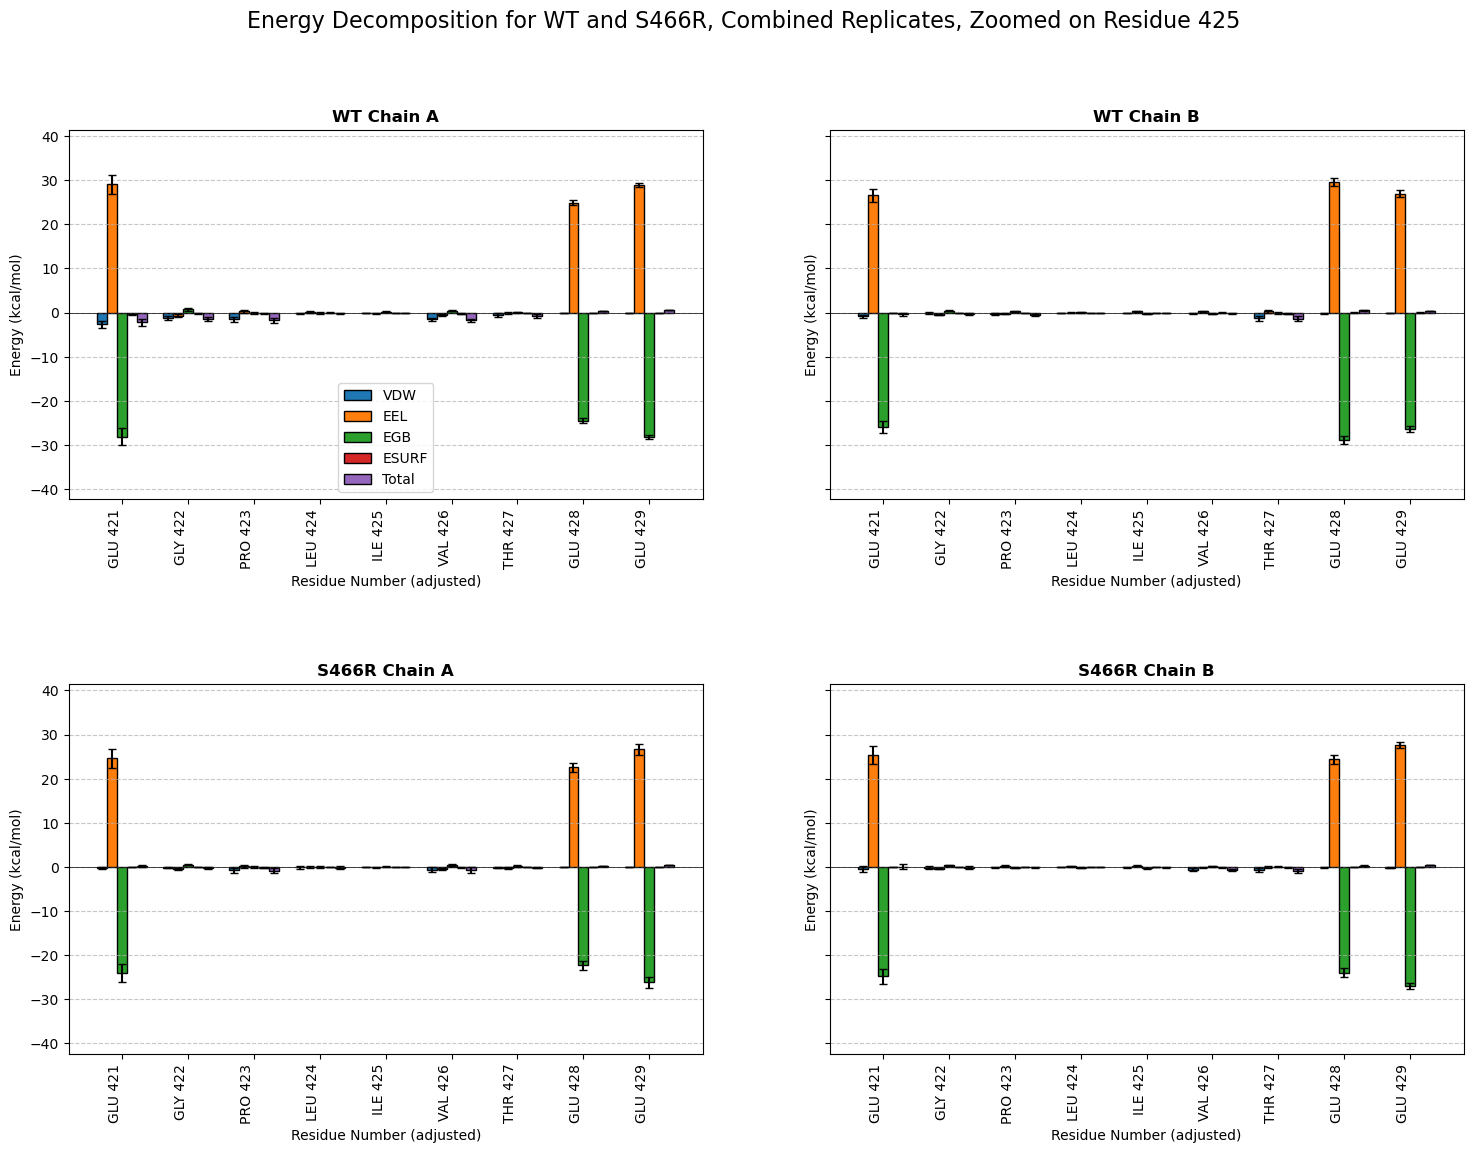

In [45]:

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Define plots
plots = [
    (df_wt_monoA, ax1, 'WT Chain A'),
    (df_wt_monoB, ax2, 'WT Chain B'),
    (df_S466R_monoA, ax3, 'S466R Chain A'),
    (df_S466R_monoB, ax4, 'S466R Chain B'),
]

# Plotting parameters
n_terms = len(energy_terms)  # Number of energy terms (5)
bar_width = 0.15  # Width of each bar
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total']  # Short labels for legend

for df, ax, title in plots:
    # Filter for residues in the range 420-430
    filtered_df = df[(df['resid_adj'].astype(int) > 420) & (df['resid_adj'].astype(int) < 430)]
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        # Calculate x positions for this term's bars
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        # Plot bars with error bars
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label if ax == ax1 else None  # Add legend only on first subplot
        )
    
    # Customize axes
    ax.set_title(title, fontweight='bold')
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)  # Set consistent y-limits

# Add legend to the first subplot
ax1.legend(loc='best')

# Add suptitle and adjust layout
plt.suptitle('Energy Decomposition for WT and S466R, Combined Replicates, Zoomed on Residue 425', fontsize=16)

plt.subplots_adjust(hspace=0.5)
plt.show()

#### Interpretation - Differences in residue 466

In [46]:
# Merge WT and S466R DataFrames on 'resid_adj' and 'chain' to get common residues
common_df = wt_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']].merge(
    S466R_decomp_combined_df[['Residue', 'resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']],
    on=['resid_adj', 'chain'],
    suffixes=('_WT', '_S466R')
)

# Calculate the differences (WT - S466R)
common_df['EEL_diff'] = common_df['Electrostatic_mean_WT'] - common_df['Electrostatic_mean_S466R']
common_df['VDW_diff'] = common_df['van der Waals_mean_WT'] - common_df['van der Waals_mean_S466R']
common_df['EGB_diff'] = common_df['Polar Solvation_mean_WT'] - common_df['Polar Solvation_mean_S466R']
common_df['ESURF_diff'] = common_df['Non-Polar Solv._mean_WT'] - common_df['Non-Polar Solv._mean_S466R']

In [47]:
common_df[common_df['resid_adj'] == '461']

,Residue_WT,resid_adj,chain,Electrostatic_mean_WT,Polar Solvation_mean_WT,van der Waals_mean_WT,Non-Polar Solv._mean_WT,Residue_S466R,Electrostatic_mean_S466R,Polar Solvation_mean_S466R,van der Waals_mean_S466R,Non-Polar Solv._mean_S466R,EEL_diff,VDW_diff,EGB_diff,ESURF_diff
66,L:A:VAL:326,461,A,-0.728852,0.716474,-1.379208,-0.286653,L:A:VAL:326,-0.660619,0.637971,-0.430170,-0.064395,-0.068234,-0.949039,0.078503,-0.222259
138,L:B:VAL:326,461,B,-0.742349,0.739251,-2.040742,-0.456088,L:B:VAL:326,-0.672658,0.668856,-1.326653,-0.179764,-0.069691,-0.714088,0.070396,-0.276324


Residues not in both dfs

In [48]:
# Perform an outer merge to include all residues and their associated columns
merged_df = wt_decomp_combined_df[['resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']].merge(
    S466R_decomp_combined_df[['resid_adj', 'chain', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']],
    on=['resid_adj', 'chain'],
    how='outer',
    indicator=True,
    suffixes=('_WT', '_S466R')
)

# Filter for residues that are only in one DataFrame
non_common_df = merged_df[merged_df['_merge'] != 'both'].copy()

# Create a column to indicate which DataFrame the residue is from
non_common_df['Source'] = non_common_df['_merge'].map({
    'left_only': 'WT',
    'right_only': 'S466R'
})

# Create consolidated columns for the energy terms, prioritizing WT or S466R values
non_common_df['Electrostatic_mean'] = non_common_df['Electrostatic_mean_WT'].fillna(non_common_df['Electrostatic_mean_S466R'])
non_common_df['Polar Solvation_mean'] = non_common_df['Polar Solvation_mean_WT'].fillna(non_common_df['Polar Solvation_mean_S466R'])
non_common_df['van der Waals_mean'] = non_common_df['van der Waals_mean_WT'].fillna(non_common_df['van der Waals_mean_S466R'])
non_common_df['Non-Polar Solv._mean'] = non_common_df['Non-Polar Solv._mean_WT'].fillna(non_common_df['Non-Polar Solv._mean_S466R'])

# Select relevant columns for the final table
result_df = non_common_df[['resid_adj', 'chain', 'Source', 'Electrostatic_mean', 'Polar Solvation_mean', 'van der Waals_mean', 'Non-Polar Solv._mean']]

# Print the table
result_df

,resid_adj,chain,Source,Electrostatic_mean,Polar Solvation_mean,van der Waals_mean,Non-Polar Solv._mean
1,331,A,WT,-25.373513,25.069501,-0.023693,0.000000
10,330,A,WT,-0.553234,0.536317,-0.051617,-0.000140
70,331,B,WT,-27.350240,26.957136,-0.046297,0.000000
80,330,B,WT,-0.381392,0.369152,-0.033458,-0.000015
129,560,B,WT,0.151118,-0.137999,-0.028403,0.000000
184,384,A,S466R,-0.205379,0.199232,-0.000120,0.000000
185,467,A,S466R,-0.561647,0.536517,-0.012201,0.000000
186,564,A,S466R,0.299935,-0.286916,-0.021642,0.000000
187,640,A,S466R,0.159391,-0.139521,-0.053723,-0.002106
188,374,A,S466R,0.119381,-0.111747,-0.010180,0.000000


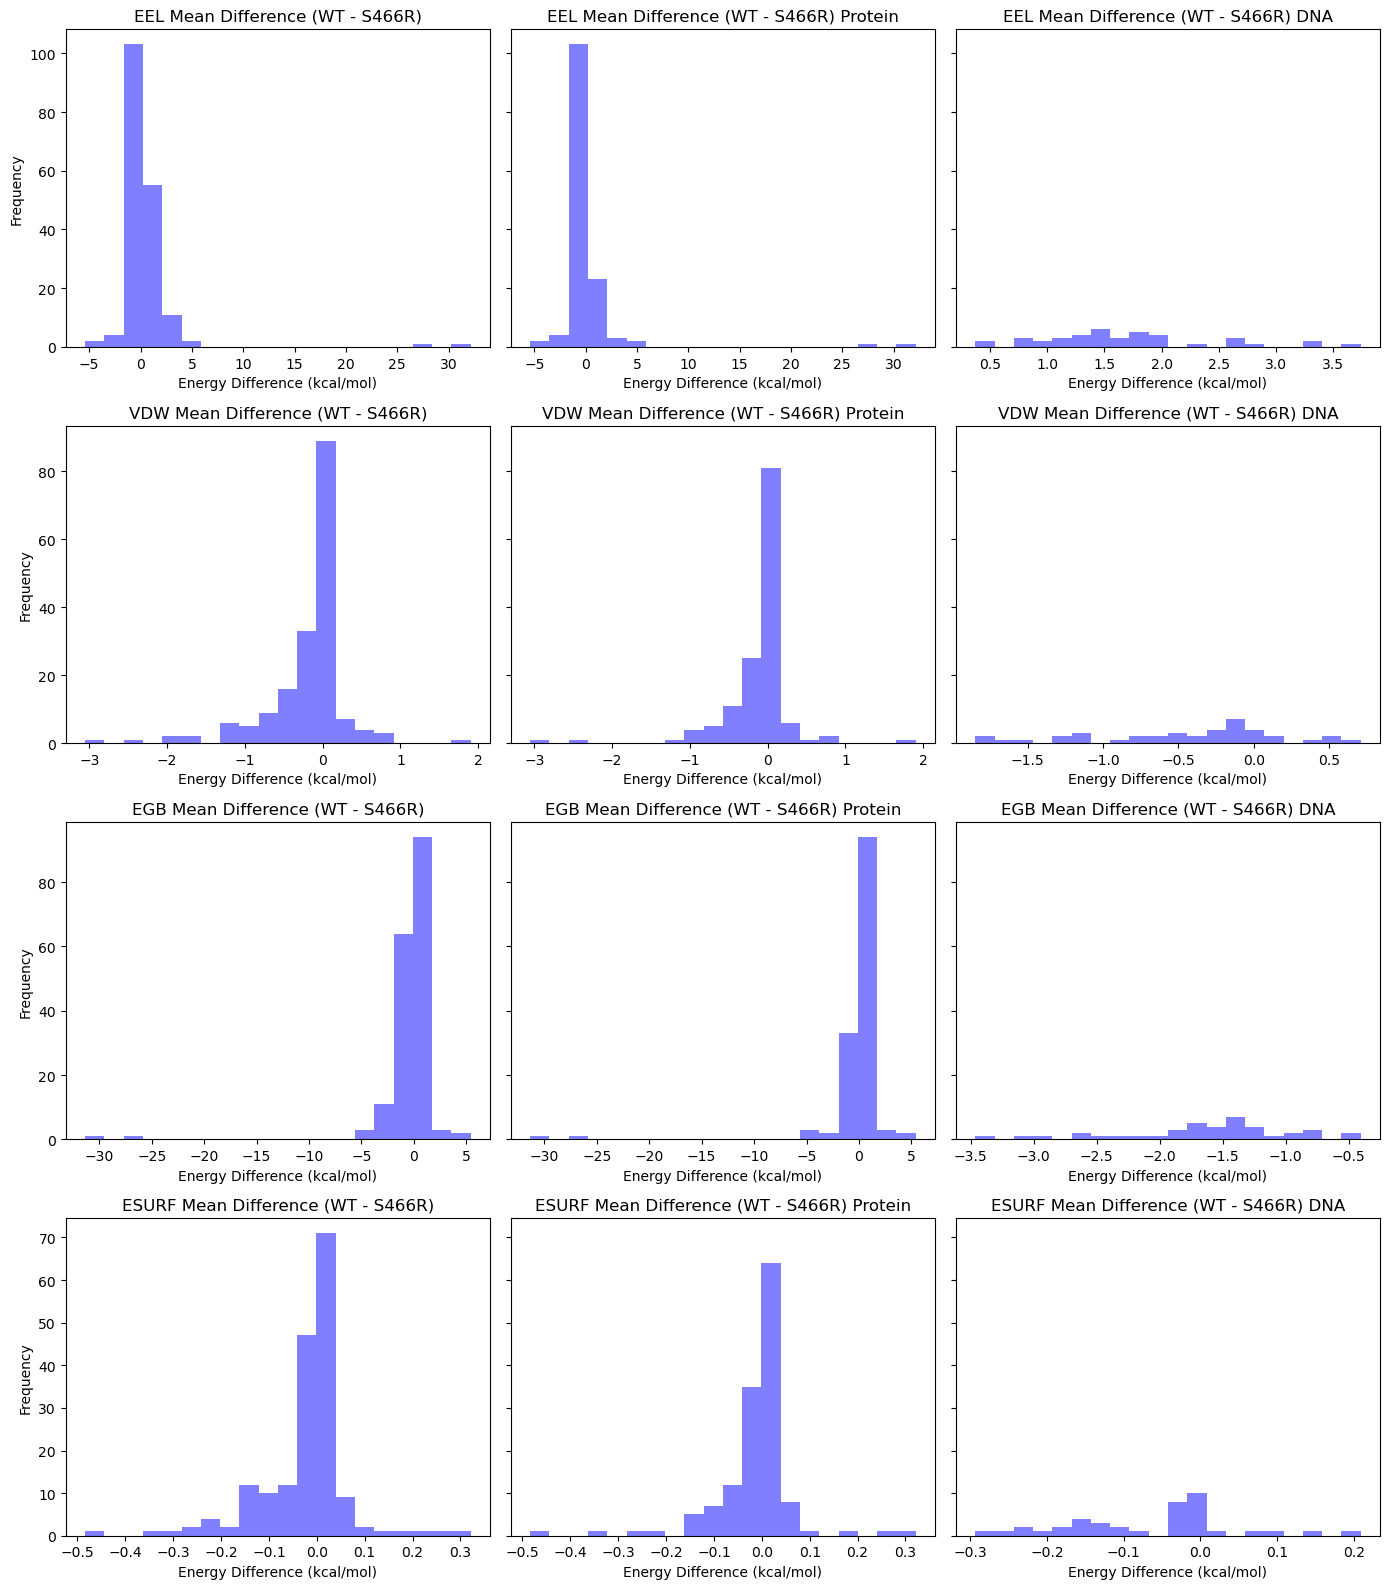

In [49]:
# columns ending in '_diff'
diff_columns = common_df.filter(like='_diff').columns
n_rows = len(diff_columns)

fig, axes = plt.subplots(n_rows, 3, figsize=(14, 4 * n_rows), sharey='row', squeeze=False)

for row, diff_col in enumerate(diff_columns):
    # Extract the energy term name
    term_name = diff_col.replace('_diff', '')
    
    # All residues
    axes[row, 0].hist(common_df[diff_col], bins=20, alpha=0.5, color='blue')
    axes[row, 0].set_title(f'{term_name} Mean Difference (WT - S466R)')
    axes[row, 0].set_xlabel('Energy Difference (kcal/mol)')
    axes[row, 0].set_ylabel('Frequency')
    
    # Protein chains (A, B)
    axes[row, 1].hist(common_df[diff_col][common_df['chain'].isin(['A', 'B'])], bins=20, alpha=0.5, color='blue')
    axes[row, 1].set_title(f'{term_name} Mean Difference (WT - S466R) Protein')
    axes[row, 1].set_xlabel('Energy Difference (kcal/mol)')
    
    # DNA chains (C, D)
    axes[row, 2].hist(common_df[diff_col][common_df['chain'].isin(['C', 'D'])], bins=20, alpha=0.5, color='blue')
    axes[row, 2].set_title(f'{term_name} Mean Difference (WT - S466R) DNA')
    axes[row, 2].set_xlabel('Energy Difference (kcal/mol)')

plt.tight_layout()
plt.show()

EEL outlyers

In [50]:
common_df[common_df['EEL_diff'] > 3][['resid_adj', 'chain', 'Electrostatic_mean_WT', 'Electrostatic_mean_S466R', 'EEL_diff']].sort_values('EEL_diff', ascending=False)

,resid_adj,chain,Electrostatic_mean_WT,Electrostatic_mean_S466R,EEL_diff
124,466,B,-0.782350,-32.928999,32.146648
53,466,A,-0.920719,-28.963766,28.043047
83,428,B,29.555958,24.361983,5.193975
14,421,A,29.022399,24.620559,4.401840
3,418,A,-28.401906,-32.227009,3.825103
163,6,D,-2.463796,-6.205715,3.741919
157,7,C,-3.385413,-6.753752,3.368340
155,6,C,-0.491610,-3.774644,3.283034


VDW outliers

In [51]:
common_df[common_df['VDW_diff'] > 1][
    ['resid_adj', 'chain', 'van der Waals_mean_WT', 'van der Waals_mean_S466R', 'VDW_diff']].sort_values('VDW_diff', ascending=False)

,resid_adj,chain,van der Waals_mean_WT,van der Waals_mean_S466R,VDW_diff
3,418,A,-1.408623,-3.311713,1.90309


In [52]:
common_df[common_df['VDW_diff'] < -1.5][
    ['resid_adj', 'chain', 'van der Waals_mean_WT', 'van der Waals_mean_S466R', 'VDW_diff']].sort_values('VDW_diff', ascending=False)

,resid_adj,chain,van der Waals_mean_WT,van der Waals_mean_S466R,VDW_diff
152,19,C,-2.358500,-0.789661,-1.568839
155,6,C,-3.088114,-1.473483,-1.614631
157,7,C,-5.559581,-3.733383,-1.826198
158,8,C,-5.768952,-3.920768,-1.848184
14,421,A,-2.688174,-0.307954,-2.380220
70,418,B,-6.049578,-2.994963,-3.054614


EGB outliers

In [53]:
common_df[common_df['EGB_diff'] < -3][
    ['resid_adj', 'chain', 'Polar Solvation_mean_WT', 'Polar Solvation_mean_S466R', 'EGB_diff']
].sort_values('EGB_diff', ascending=True)

,resid_adj,chain,Polar Solvation_mean_WT,Polar Solvation_mean_S466R,EGB_diff
124,466,B,0.747924,32.089734,-31.341810
53,466,A,0.876055,28.352957,-27.476903
83,428,B,-28.858550,-23.976294,-4.882255
14,421,A,-28.140233,-24.122984,-4.017249
3,418,A,27.720366,31.526600,-3.806234
163,6,D,2.313001,5.777598,-3.464597
157,7,C,3.297399,6.421430,-3.124032


In [54]:
common_df[(common_df['EGB_diff'] < -3)][
    ['resid_adj', 'chain', 'Polar Solvation_mean_WT', 'Polar Solvation_mean_S466R', 'EGB_diff']
].sort_values('EGB_diff', ascending=True)

,resid_adj,chain,Polar Solvation_mean_WT,Polar Solvation_mean_S466R,EGB_diff
124,466,B,0.747924,32.089734,-31.341810
53,466,A,0.876055,28.352957,-27.476903
83,428,B,-28.858550,-23.976294,-4.882255
14,421,A,-28.140233,-24.122984,-4.017249
3,418,A,27.720366,31.526600,-3.806234
163,6,D,2.313001,5.777598,-3.464597
157,7,C,3.297399,6.421430,-3.124032


Energy metrics breakdown per DNA chain

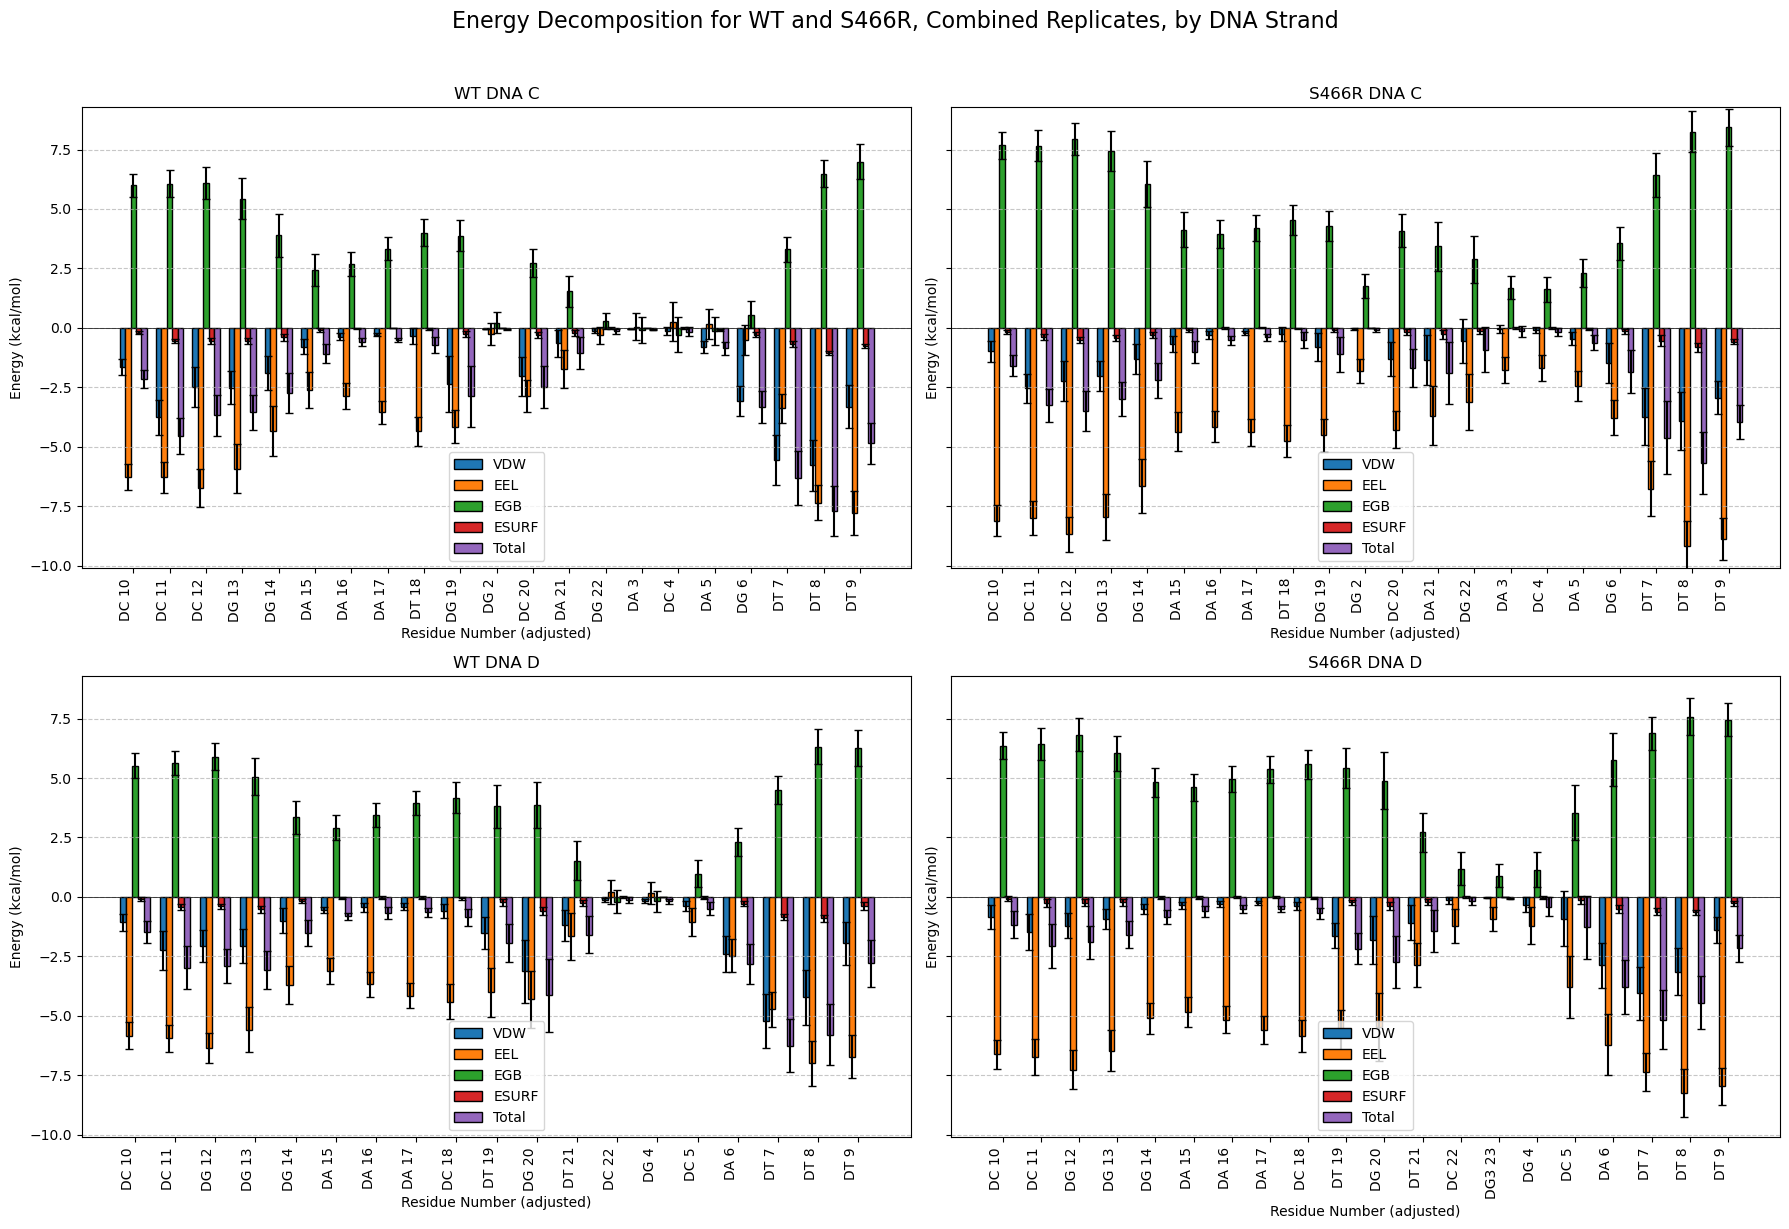

In [55]:
df_wt_dnaC = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_dnaC= S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "C"].sort_values(by=["resid_adj"], ascending=True)

df_wt_dnaD = wt_decomp_combined_df[wt_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)
df_S466R_dnaD = S466R_decomp_combined_df[S466R_decomp_combined_df["chain"] == "D"].sort_values(by=["resid_adj"], ascending=True)

energy_terms = [
    'van der Waals_mean', 'Electrostatic_mean', 'Polar Solvation_mean',
    'Non-Polar Solv._mean', 'TOTAL_mean'
]
std_terms = [
    'van der Waals_std', 'Electrostatic_std', 'Polar Solvation_std',
    'Non-Polar Solv._std', 'TOTAL_std'
]

# Find global min and max across all energy terms
all_data = []
for df in [df_wt_dnaC, df_S466R_dnaC, df_wt_dnaD, df_S466R_dnaD]:
    for term in energy_terms:
        all_data.append(df[term].values)
global_min = min([np.nanmin(data) for data in all_data]) * 1.1  
global_max = max([np.nanmax(data) for data in all_data]) * 1.1  

fig, axes = plt.subplots(2, 2, figsize=(18, 12), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

plots = [
    (df_wt_dnaC, ax1, 'WT DNA C'),
    (df_S466R_dnaC, ax2, 'S466R DNA C'),
    (df_wt_dnaD, ax3, 'WT DNA D'),
    (df_S466R_dnaD, ax4, 'S466R DNA D'),
]

# Plotting parameters
n_terms = len(energy_terms)  
bar_width = 0.15 
labels = ['VDW', 'EEL', 'EGB', 'ESURF', 'Total'] 

for df, ax, title in plots:
    filtered_df = df.copy()
    filtered_df['resid_adj'] = pd.to_numeric(filtered_df['resid_adj'])
    
    # Get residue positions and labels
    residues = filtered_df['resid_adj'].values
    res_labels = [f"{resnm} {resid}" for resnm, resid in zip(filtered_df['resnm'], filtered_df['resid_adj'])]
    n_residues = len(residues)
    
    # Set x positions for bars
    x = np.arange(n_residues)  # Base positions for residues
    for i, (term, std, label) in enumerate(zip(energy_terms, std_terms, labels)):
        x_pos = x + i * bar_width - (n_terms - 1) * bar_width / 2
        ax.bar(
            x_pos,
            filtered_df[term],
            yerr=filtered_df[std],
            width=bar_width,
            edgecolor='black',
            capsize=3,
            label=label
        )
    
    # Customize axes
    ax.set_title(title)
    ax.set_ylabel('Energy (kcal/mol)')
    ax.set_xlabel('Residue Number (adjusted)')
    ax.set_xticks(x)
    ax.set_xticklabels(res_labels, rotation=90, ha='right')
    ax.legend(loc='best')
    ax.grid(True, axis='y', linestyle='--', alpha=0.7)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.set_ylim(global_min, global_max)

plt.suptitle('Energy Decomposition for WT and S466R, Combined Replicates, by DNA Strand', fontsize=16, y=1.02)

plt.tight_layout()
plt.show()

#### Interpretation - Energy metrics outliers